# Getting started on lab 3 

For this lab, the goal is to compute and model a super nova light curve. To do this, you have been given 433 fits images from the 1.6m Korean Microlensing Telescope network (KMTnet). Here is some more information https://noirlab.edu/public/programs/ctio/kmtnet-16m-telescope/

In [54]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 12})

from os import listdir
from os.path import isfile, join
from datetime import datetime
from matplotlib.colors import LogNorm
import warnings
warnings.filterwarnings('ignore', category=UserWarning, append=True)

### Let's start by looking at one of the fits file headers

In [55]:
imfile = 'AST325-326-SN-20151030.0653.fits'
fits.open(imfile)[0].header

SIMPLE  =                    T / Written by IDL:  Sat Oct 29 22:01:42 2022      
BITPIX  =                   16 / 16-bit twos complement binary integer          
NAXIS   =                    2 / Number of axes                                 
NAXIS1  =                 2251 /                                                
NAXIS2  =                 2251 /                                                
CTYPE1  = 'RA---TAN-SIP'       / TAN (gnomic) projection + SIP distortions      
CTYPE2  = 'DEC--TAN-SIP'       / TAN (gnomic) projection + SIP distortions      
CRPIX1  =        2901.49999352 / X reference pixel                              
CRPIX2  =        3581.50000250 / Y reference pixel                              
CRVAL1  =        14.0146384555 / RA  of reference point                         
CRVAL2  =       -36.7706563771 / DEC of reference point                         
CDELT1  =   -0.000111111111111 /                                                
CDELT2  =    0.0001111111111

### Some basics about the data we can get from the header

['AST325-326-SN-20151004.3792.fits', 'AST325-326-SN-20151008.9958.fits', 'AST325-326-SN-20151026.0264.fits', 'AST325-326-SN-20151008.5583.fits', 'AST325-326-SN-20151012.1208.fits', 'AST325-326-SN-20151009.0868.fits', 'AST325-326-SN-20151012.1375.fits', 'AST325-326-SN-20151027.1743.fits', 'AST325-326-SN-20151004.6354.fits', 'AST325-326-SN-20150928.1257.fits', 'AST325-326-SN-20151029.2604.fits', 'AST325-326-SN-20150922.6569.fits', 'AST325-326-SN-20151002.6236.fits', 'AST325-326-SN-20151008.3743.fits', 'AST325-326-SN-20150930.3778.fits', 'AST325-326-SN-20151004.3243.fits', 'AST325-326-SN-20150922.2410.fits', 'AST325-326-SN-20151029.2764.fits', 'AST325-326-SN-20151027.0896.fits', 'AST325-326-SN-20151009.0722.fits', 'AST325-326-SN-20150928.6514.fits', 'AST325-326-SN-20151029.1826.fits', 'AST325-326-SN-20151008.5403.fits', 'AST325-326-SN-20151008.1528.fits', 'AST325-326-SN-20151019.5396.fits', 'AST325-326-SN-20150922.2083.fits', 'AST325-326-SN-20151024.4271.fits', 'AST325-326-SN-20151006.169

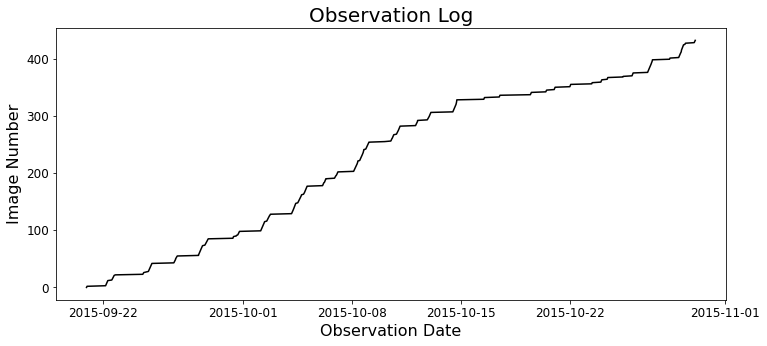

In [3]:
#When was the data taken?

#get all of the files 
img_files = [f for f in listdir('.') if isfile(join('.', f)) and 'fits' in f]

print(img_files)

file_times = []
for f in img_files:
    header = fits.open(f)[0].header
    dt = datetime.fromisoformat(header["DATE-OBS"])
    file_times.append(dt)

#sort files by the same way
file_times, img_files = zip(*sorted(zip(file_times, img_files)))

img_files = np.array(img_files)
file_times = np.array(file_times)

plt.figure(figsize=(12,5))
plt.plot(file_times, np.arange(file_times.size), color = 'k')
plt.ylabel("Image Number", size = 16)
plt.xlabel("Observation Date", size = 16)
plt.title("Observation Log", size = 20)
plt.show()

### The data is in a slightly odd format, let's take a closer look

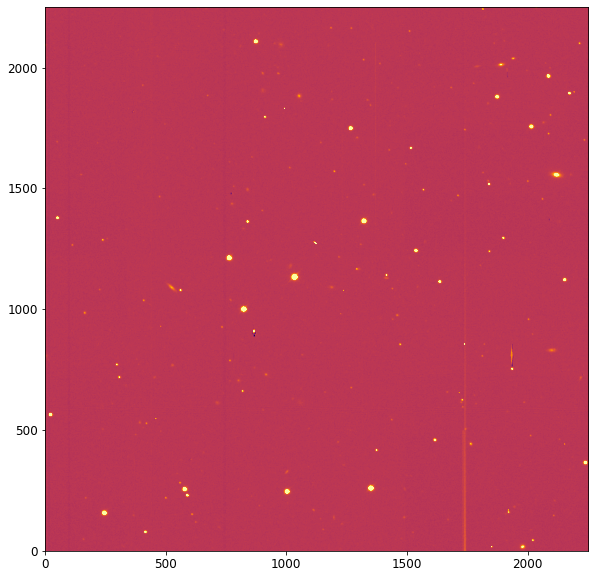

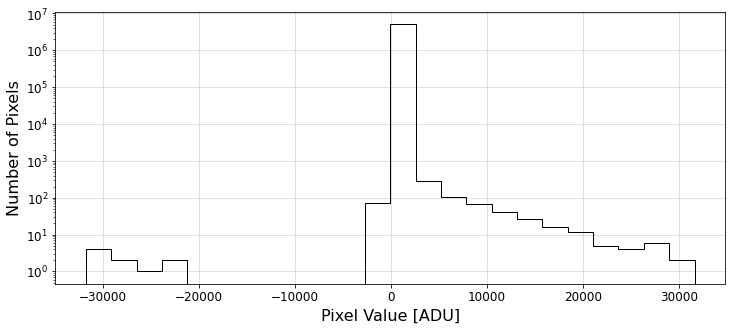

MAX VALUE 31628
MIN VALUE -31794


In [4]:
def read_file1(filename):
    return fits.open(filename)[0].data

data1 = read_file1(img_files[2])
plt.figure(figsize=(10,10))
plt.imshow(data1,
           vmin = -100,
           vmax = 1e2,
           origin = 'lower',
           cmap = 'inferno')
plt.show()

plt.figure(figsize=(12,5))
plt.hist(data1.flatten(), bins = 'sturges', color = 'k', histtype='step')
plt.grid(alpha=0.5)
plt.yscale('log')
plt.xlabel("Pixel Value [ADU]", size = 16)
plt.ylabel("Number of Pixels", size = 16)
plt.show()

print(f"MAX VALUE {np.max(data1)}\nMIN VALUE {np.min(data1)}")
row = np.where(data1 == np.min(data1))[0][0]

**By plotting a single row, we can see that some of the brightest stars have negative drops at their centers. This is because of an overflow error when the unsigned integer CCD images were converted to signed integer images after dark subtraction.**


In [58]:
0b11111111 #[-127, 127]
#[0, 2**16]
#[-2**15, 2**15]

127

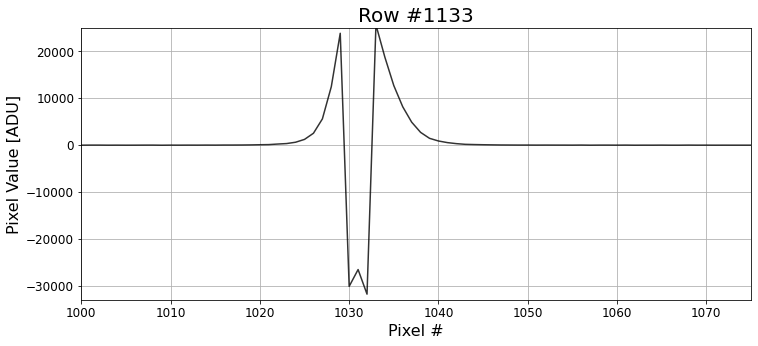

In [5]:


plt.figure(figsize= (12,5))
plt.plot(data1[row,:], color = 'k', alpha = 0.8)
plt.ylim(-33e3,25e3)
plt.xlim(1000,1075)
plt.title(f"Row #{row}", size = 20)
plt.grid()
plt.ylabel("Pixel Value [ADU]", size = 16)
plt.xlabel("Pixel #", size = 16)
plt.show()

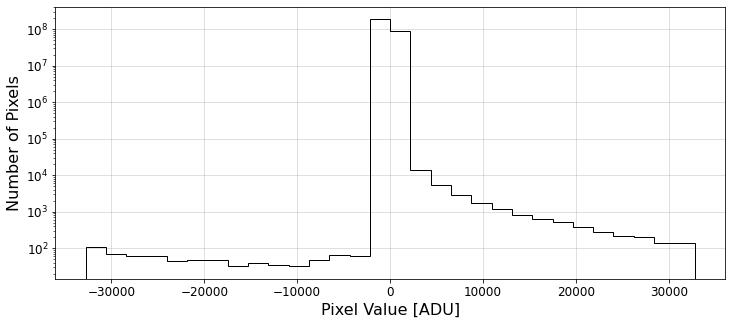

In [6]:
full_data = np.empty((len(img_files)//8, *data1.shape), dtype = data1.dtype)
for i, file in enumerate(img_files[:len(img_files)//8]):
    full_data[i] = read_file1(file)

plt.figure(figsize=(12,5))
plt.hist(full_data.flatten(), bins = 'sturges', color = 'k', histtype='step')
plt.grid(alpha=0.5)
plt.yscale('log')
plt.xlabel("Pixel Value [ADU]", size = 16)
plt.ylabel("Number of Pixels", size = 16)
plt.show()

del full_data

### So what is happening here? (Class discussion)

**To fix the overflow issue, we can assume a threshold such that only stars will be that negative (i.e. extract the values that likely resulted from the overflow error as opposed to regular background values) and reverse the process that initiated the overflow**

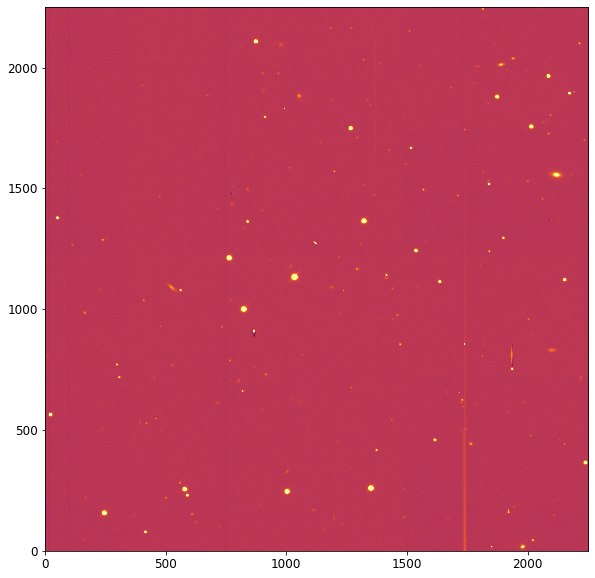

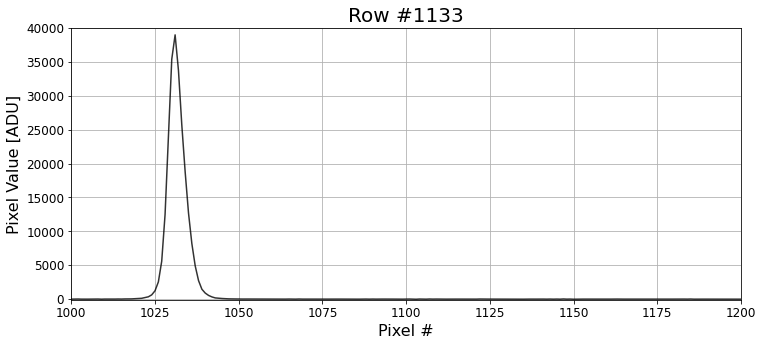

MAX VALUE 43253
MIN VALUE -553


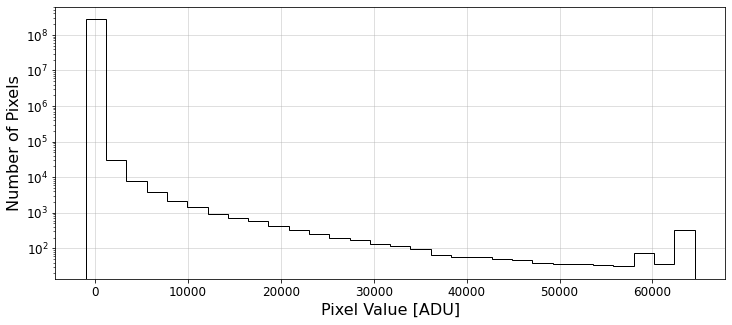

AST325-326-SN-20150920.9535.fits


In [7]:
def read_file(filename):
    hdu = fits.open(filename)[0]
    data = hdu.data.astype(int)
    data[data < -1e3] = ((2**15-1)-np.abs(data[data < -1e3])) + (2**15-1)
    return data

data1 = read_file(img_files[2])
plt.figure(figsize=(10,10))
plt.imshow(data1,
           vmin = -100,
           vmax = 1e2,
           origin = 'lower',
           cmap = 'inferno')
plt.show()

plt.figure(figsize= (12,5))
plt.plot(data1[row,:], color = 'k', alpha = 0.8)
plt.ylim(-100,40e3)
plt.xlim(1000,1200)
plt.title(f"Row #{row}", size = 20)
plt.grid()
plt.ylabel("Pixel Value [ADU]", size = 16)
plt.xlabel("Pixel #", size = 16)
plt.show()

print(f"MAX VALUE {np.max(data1)}\nMIN VALUE {np.min(data1)}")

full_data = np.empty((len(img_files)//8, *data1.shape), dtype = data1.dtype)
for i, file in enumerate(img_files[:len(img_files)//8]):
    full_data[i] = read_file(file)

plt.figure(figsize=(12,5))
plt.hist(full_data.flatten(), bins = 'sturges', color = 'k', histtype='step')
plt.grid(alpha=0.5)
plt.yscale('log')
plt.xlabel("Pixel Value [ADU]", size = 16)
plt.ylabel("Number of Pixels", size = 16)
plt.show()

print(img_files[2])
del full_data

### We can find stars on the image using the fits header

the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]


<SkyCoord (ICRS): (ra, dec) in deg
    (14.19345833, -37.04152778)>
(array(1634.05217782), array(1114.32148625))


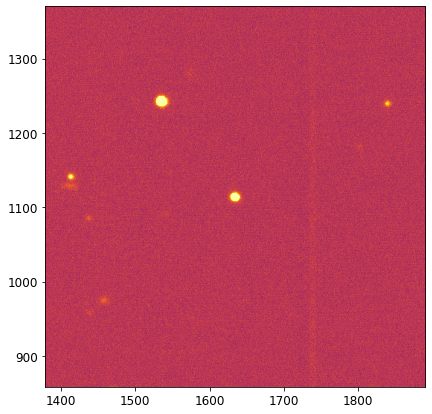

In [8]:
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord 
from astropy.wcs.utils import skycoord_to_pixel


header = fits.open(img_files[0])[0].header
data  = read_file(img_files[0])

w = WCS(header)
ref_b = SkyCoord('00h56m49.70s', '-37d01m38.31s')
ref_b = SkyCoord('00h56m46.43s', '-37d02m29.50s')

print(ref_b)
ref_pos = skycoord_to_pixel(ref_b, w)
print(ref_pos)
plt.figure(figsize = (7,7))
plt.imshow(data, origin = 'lower', cmap = 'inferno', vmin = -100, vmax = 100)
plt.xlim(ref_pos[0]-256, ref_pos[0]+256)
plt.ylim(ref_pos[1]-256, ref_pos[1]+256)
# plt.colorbar()
plt.show()

# Bad Data

You may have seen already that a lot of the images aren't exactly the best. Obviously we don't want to include those images in our final data analysis. Lets take 5-10 minutes to look at some images and seen what kind of failiure modes their are and brainstorm some ideas for weeding out bad images.

AST325-326-SN-20150924.7465.fits


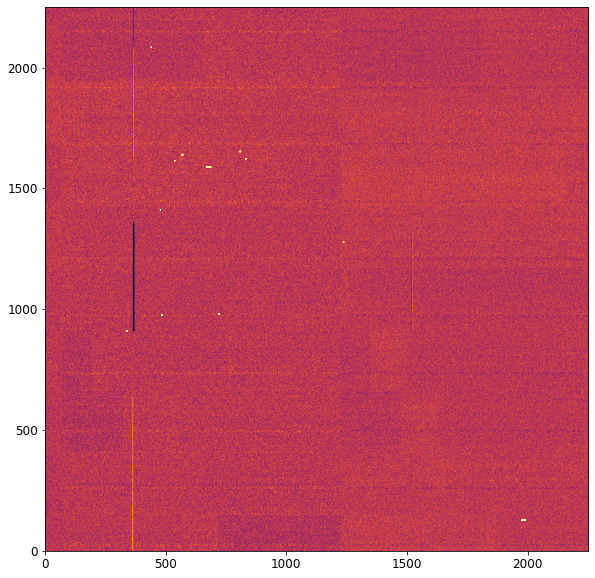

AST325-326-SN-20150930.5694.fits


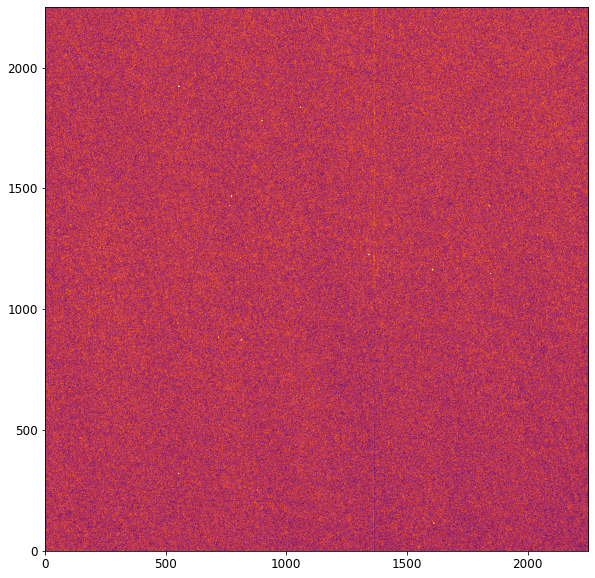

AST325-326-SN-20150930.6694.fits


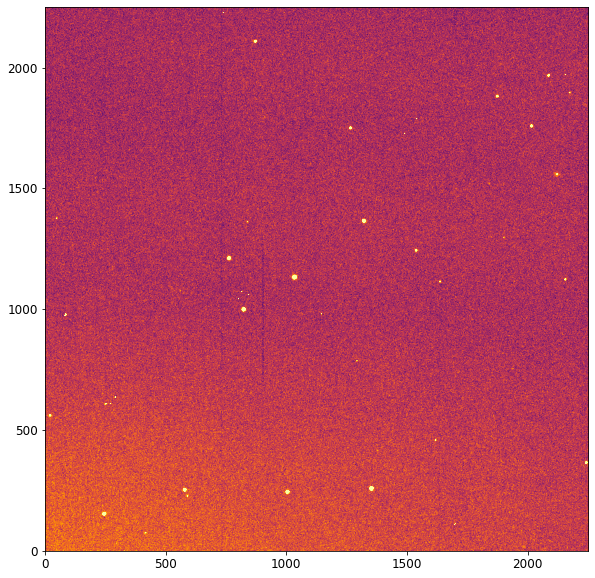

AST325-326-SN-20151004.6194.fits


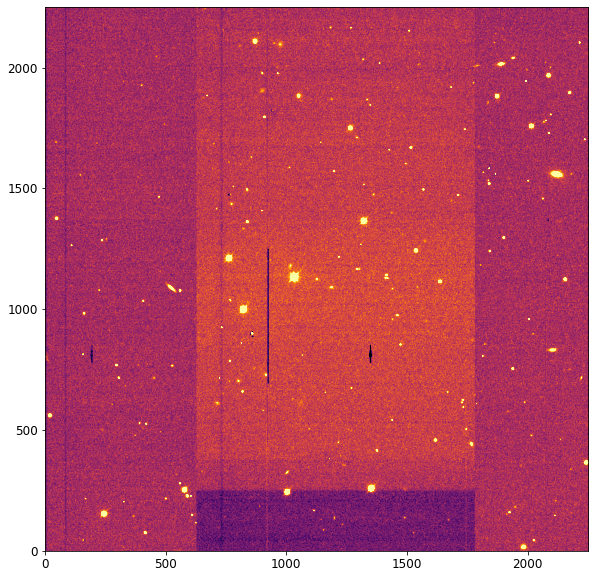

AST325-326-SN-20151006.9146.fits


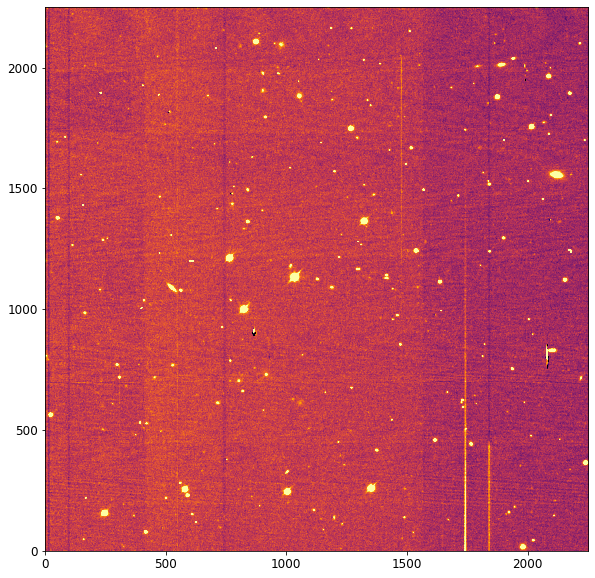

AST325-326-SN-20151008.9813.fits


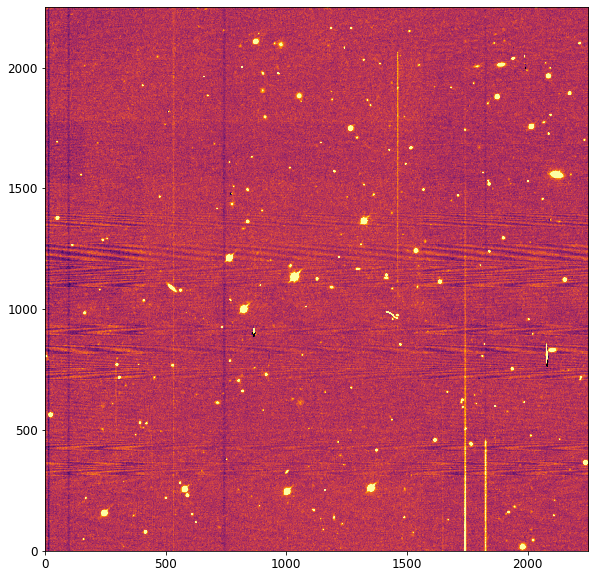

AST325-326-SN-20151004.5653.fits


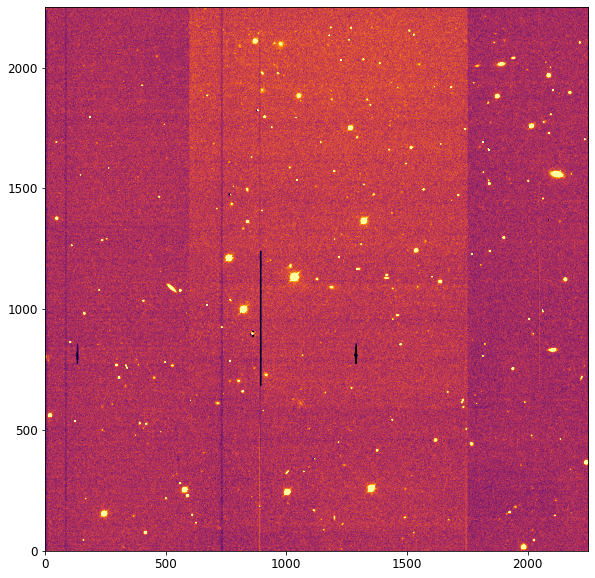

AST325-326-SN-20151004.8792.fits


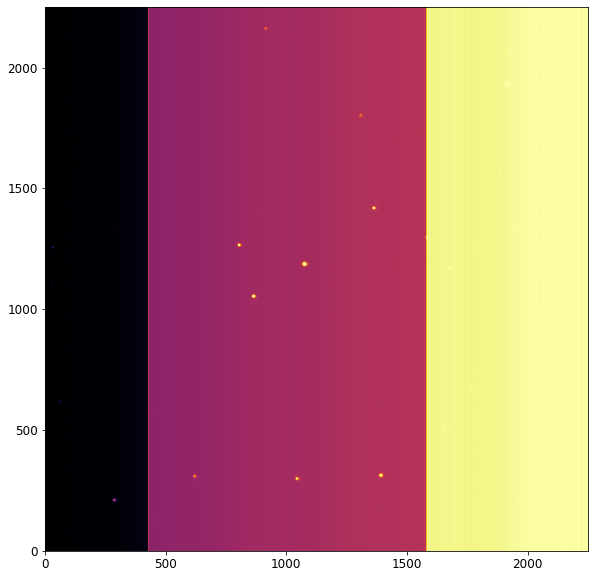

AST325-326-SN-20151008.9597.fits


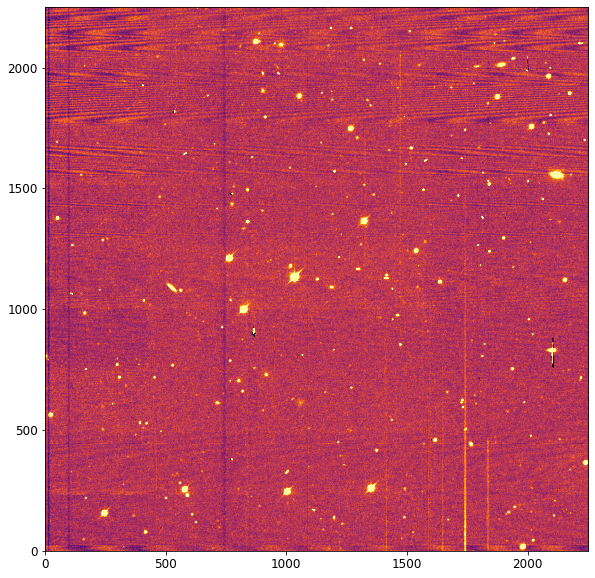

AST325-326-SN-20151026.0403.fits


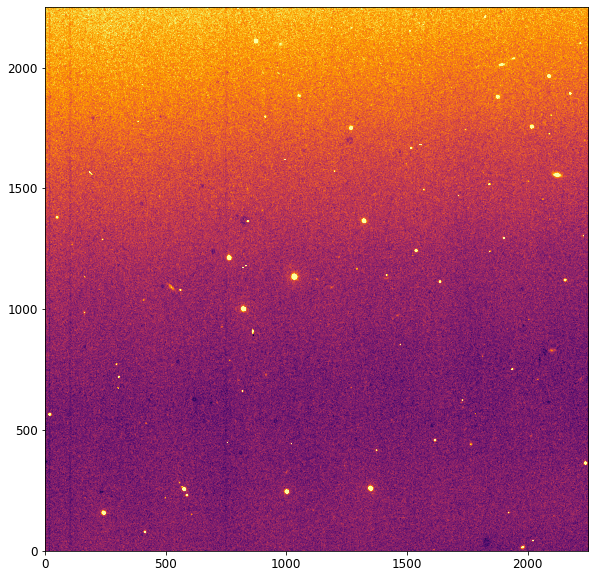

AST325-326-SN-20151026.0549.fits


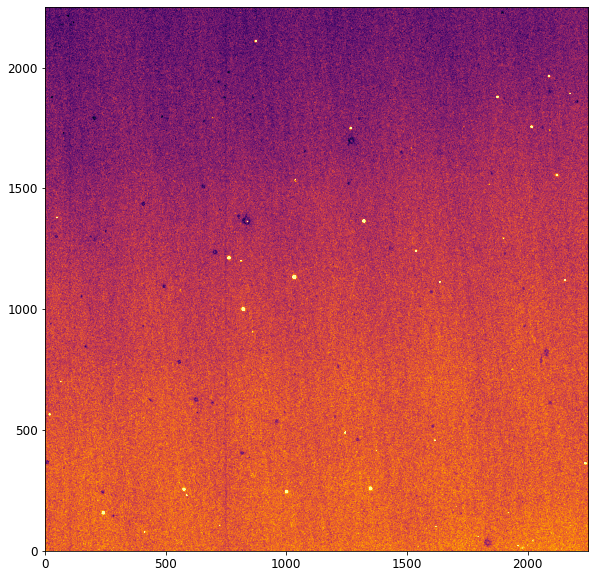

AST325-326-SN-20151012.8410.fits


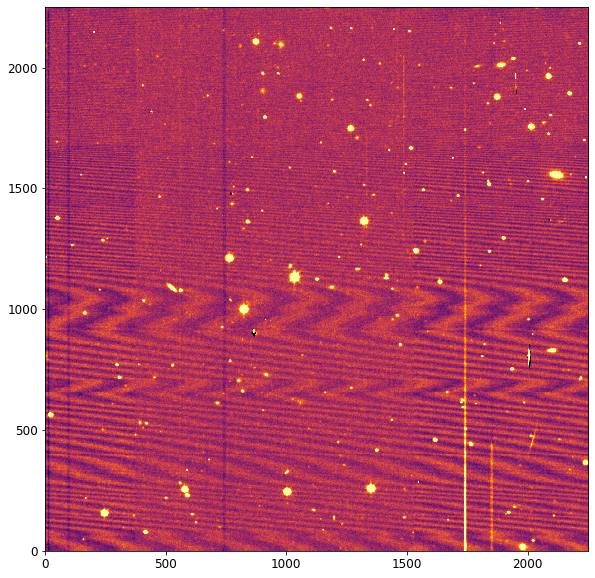

AST325-326-SN-20151012.8410.fits


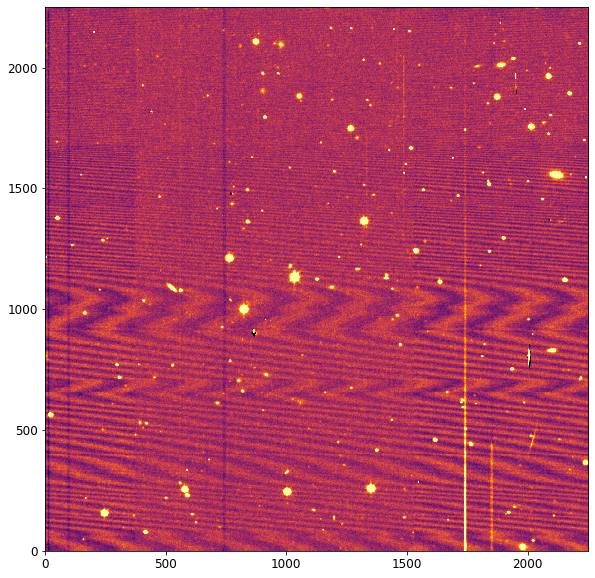

AST325-326-SN-20151004.6354.fits


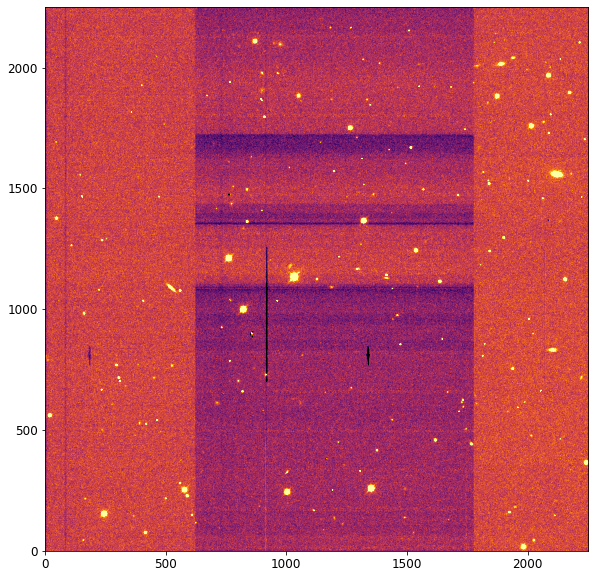

AST325-326-SN-20151010.8764.fits


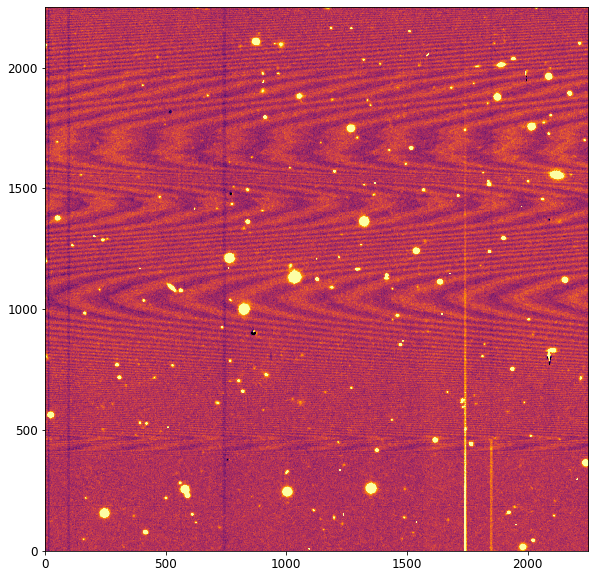

AST325-326-SN-20151011.0174.fits


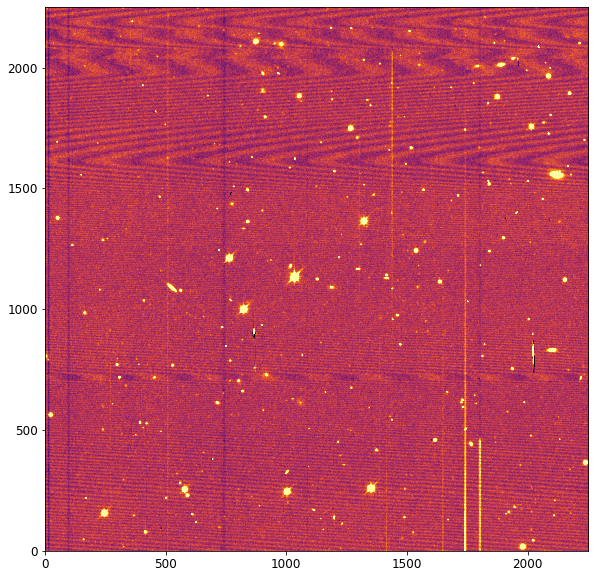

AST325-326-SN-20151011.0479.fits


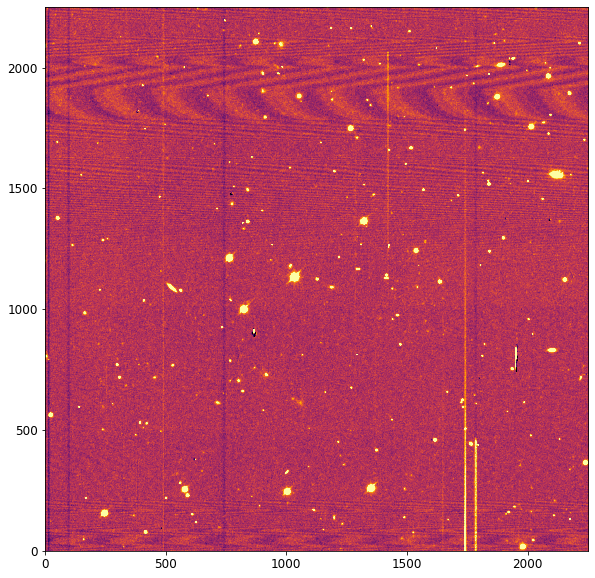

AST325-326-SN-20151017.4861.fits


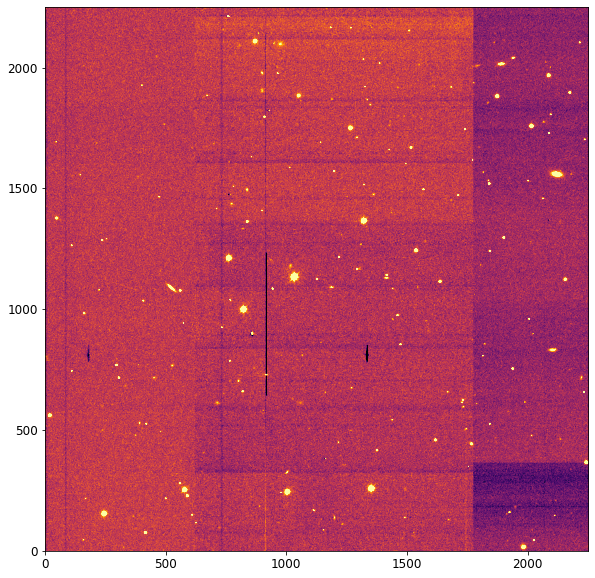

AST325-326-SN-20151029.4160.fits


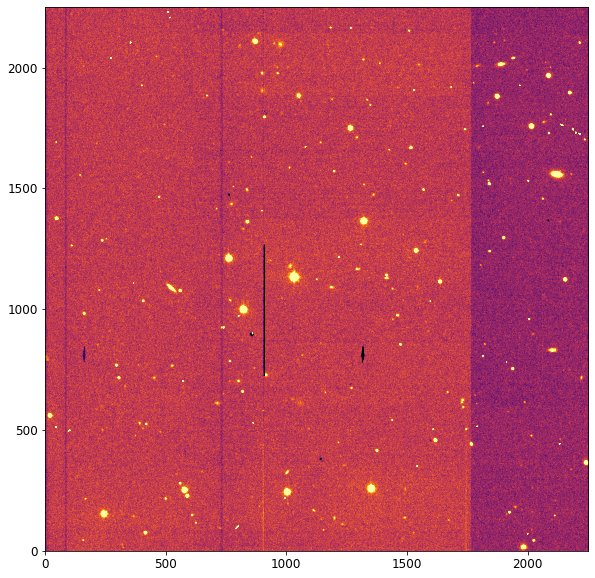

In [59]:
def plot_image(filename):
    data1 = read_file(filename)
    plt.figure(figsize=(10,10))
    plt.imshow(data1,
               vmin = np.percentile(data1,5),
               vmax = np.percentile(data1,95),
               origin = 'lower',
               cmap = 'inferno')
    plt.show()


examples = ['AST325-326-SN-20150924.7465.fits','AST325-326-SN-20150930.5694.fits',
'AST325-326-SN-20150930.6694.fits','AST325-326-SN-20151004.6194.fits',
'AST325-326-SN-20151006.9146.fits', 'AST325-326-SN-20151008.9813.fits',
'AST325-326-SN-20151004.5653.fits', 'AST325-326-SN-20151004.8792.fits',
'AST325-326-SN-20151008.9597.fits', 'AST325-326-SN-20151026.0403.fits', 
'AST325-326-SN-20151026.0549.fits', 'AST325-326-SN-20151012.8410.fits',
'AST325-326-SN-20151012.8410.fits', 'AST325-326-SN-20151004.6354.fits', 
'AST325-326-SN-20151010.8764.fits','AST325-326-SN-20151011.0174.fits', 
'AST325-326-SN-20151011.0479.fits', 'AST325-326-SN-20151017.4861.fits',
'AST325-326-SN-20151029.4160.fits']
 


for f in examples:
    print(f)
    plot_image(f)

# Class discusssion

*In groups of 3-4, come up with a method for algorithmically finding and removing these bad images*

In [47]:
from scipy.stats import skew, kurtosis
from skimage.metrics import structural_similarity as ssim
data0 =  read_file(img_files[0])
vars = np.empty(len(img_files))
means = np.empty_like(vars)
skews = np.empty_like(vars)
kurtoses = np.empty_like(vars)
sim = np.empty_like(vars)
for i, f in enumerate(img_files):
    data = read_file(f)
    vars[i] = np.var(data)
    means[i] = np.mean(data)
    skews[i] = skew(data.flatten())
    kurtoses[i] = kurtosis(data.flatten())
    sim[i] = ssim(data0, data)

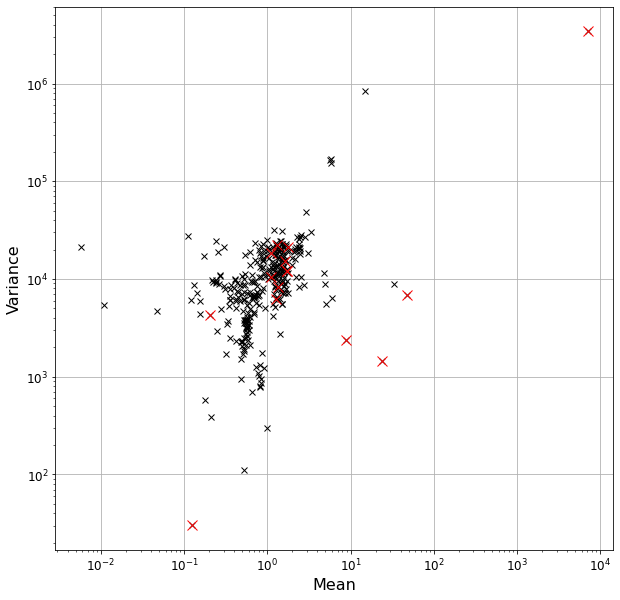

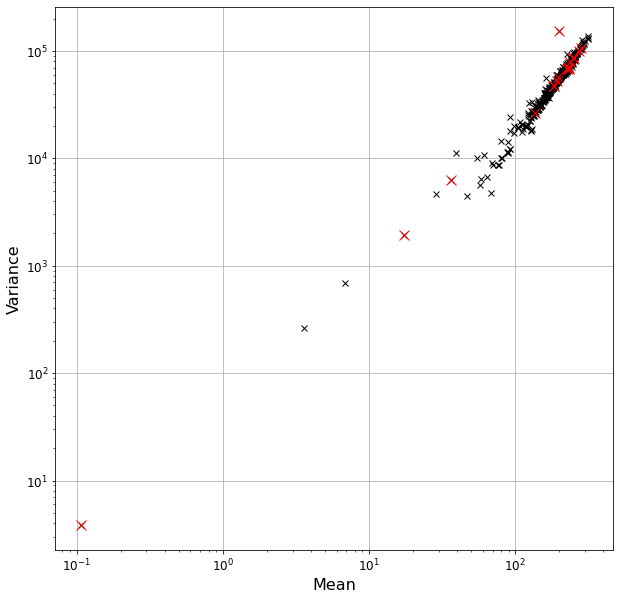

In [21]:
plt.figure(figsize=(10,10))
plt.plot(means,vars, 'x', color = 'k')
for f in examples:
    data = read_file(f)
    plt.plot(np.mean(data),np.var(data), 'x', color = 'r', ms = 10, label = 'Examples')
plt.yscale('log')
plt.xscale('log')
plt.xlabel("Mean", size = 16)
plt.ylabel("Variance", size = 16)
plt.grid()
plt.show()

plt.figure(figsize=(10,10))
plt.plot(skews,kurtoses, 'x', color = 'k')
for f in examples:
    data = read_file(f)
    plt.plot(skew(data.flatten()),kurtosis(data.flatten()), 'x', color = 'r', ms = 10, label = 'Examples')
plt.yscale('log')
plt.xscale('log')
plt.xlabel("Mean", size = 16)
plt.ylabel("Variance", size = 16)
plt.grid()
plt.show()



In [52]:
from sklearn.cluster import KMeans
def cluster_image_properties(properties, num_clusters=2):
    """
    Cluster image properties (mean, variance, skew, kurtosis) into groups using KMeans.

    Parameters:
    - properties: a list of arrays containing statistical properties for the N images.
    - num_clusters: The number of clusters for KMeans.

    Returns:
    - cluster_labels: An array of cluster labels for each image property.
    """
    # Combine the properties into a single feature matrix
    feature_matrix = np.column_stack(properties)

    # Apply KMeans clustering
    kmeans = KMeans(n_clusters=num_clusters)
    cluster_labels = kmeans.fit_predict(feature_matrix)

    return cluster_labels
NUM_CLUSTER = 20

labels = cluster_image_properties([means,vars,skews,kurtoses,sim], num_clusters=NUM_CLUSTER)

[ 0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5 13.5
 14.5 15.5 16.5 17.5 18.5 19.5 20.5]


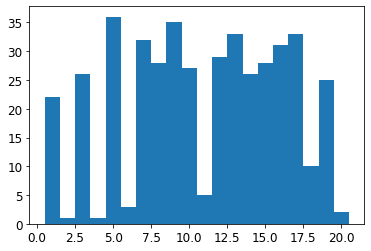

Cluster #1


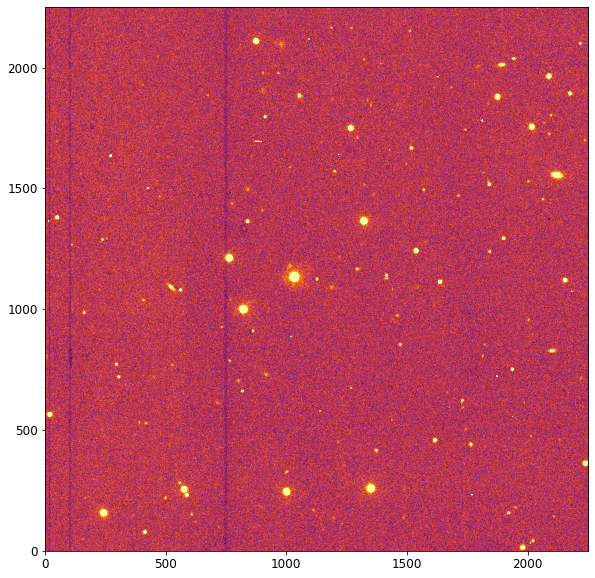

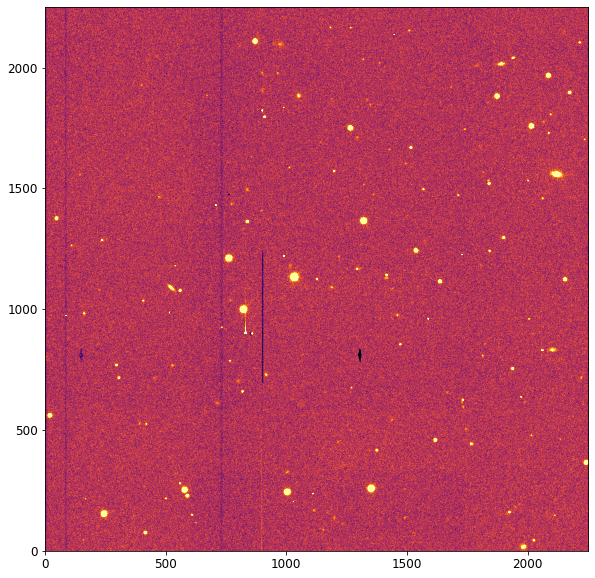

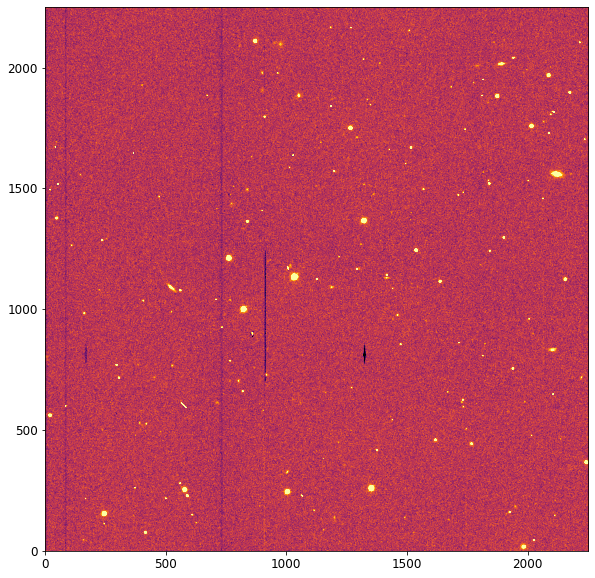

(array([112, 121, 122, 131, 135, 137, 139, 141, 144, 148, 149, 150, 152,
       183, 189, 200, 331, 334, 338, 341, 344, 345]),)
Cluster #2


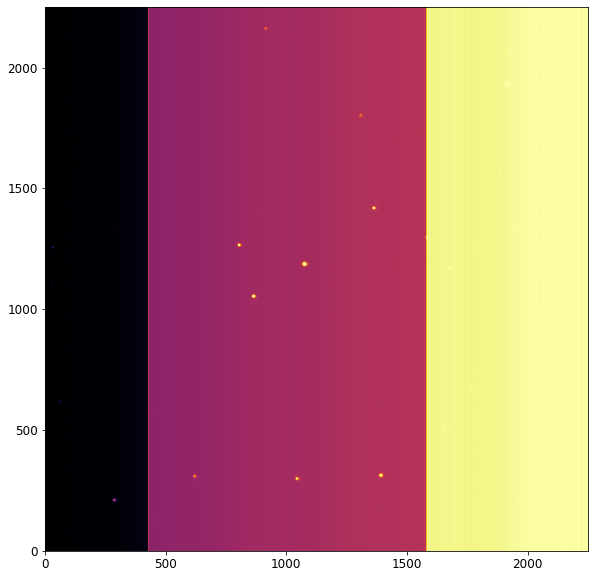

(array([163]),)
Cluster #3


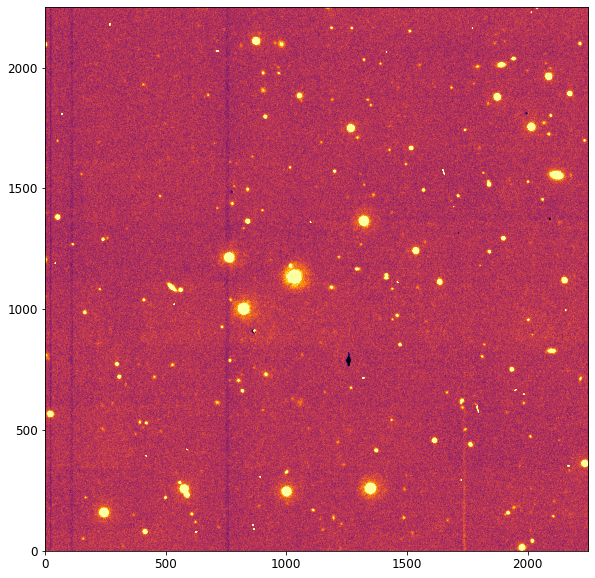

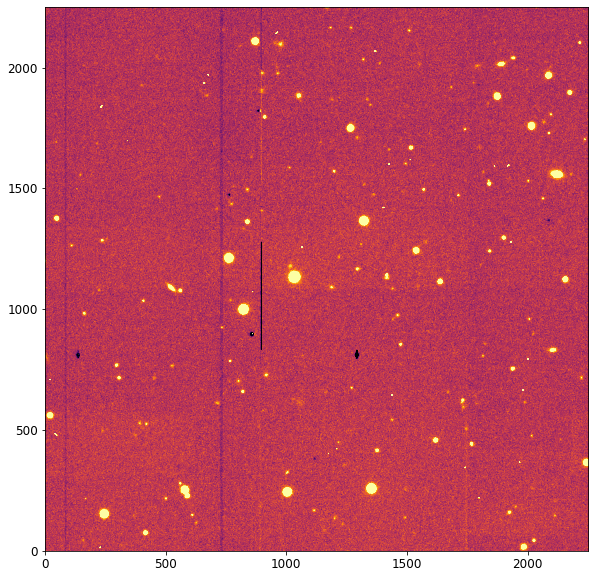

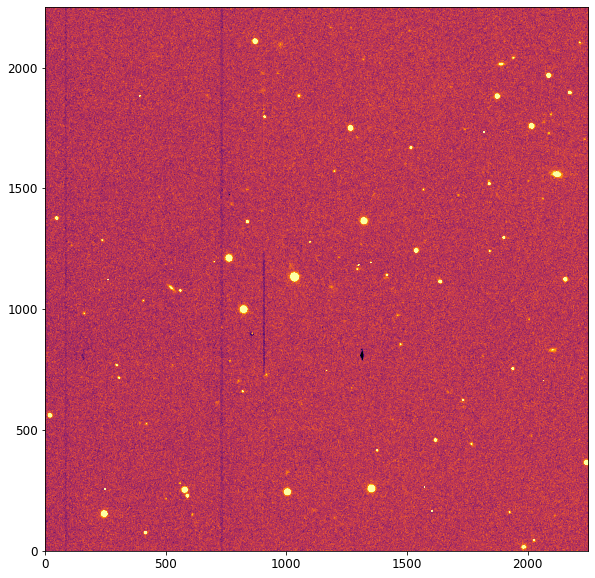

(array([ 12,  21,  23,  51,  52,  53,  54,  99, 114, 164, 181, 203, 212,
       216, 222, 223, 224, 226, 230, 256, 257, 305, 377, 396, 398, 400]),)
Cluster #4


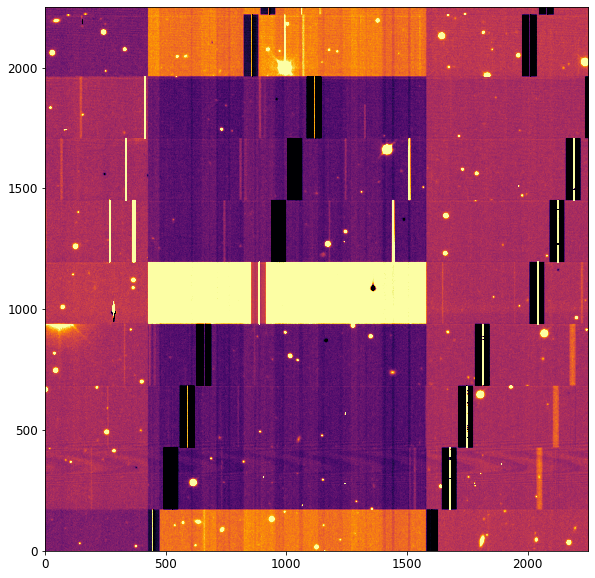

(array([273]),)
Cluster #5


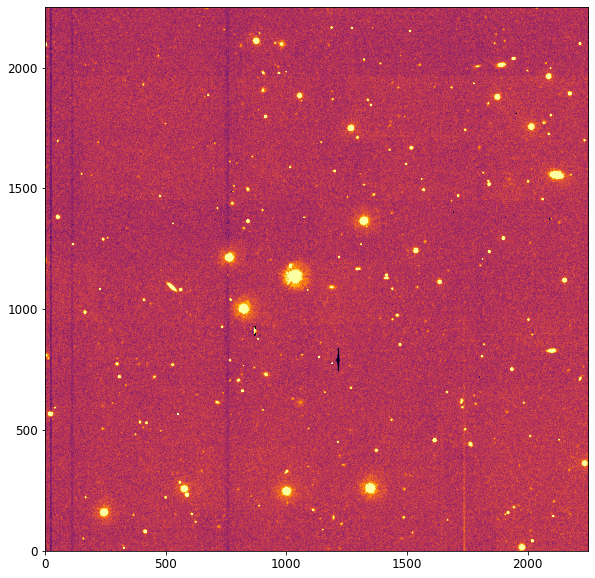

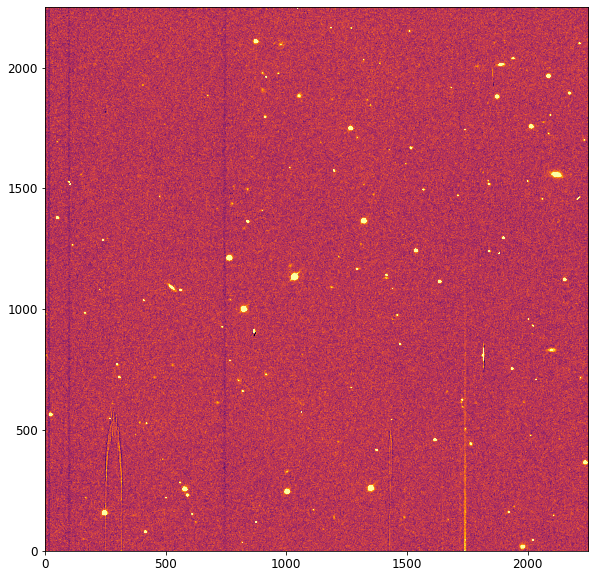

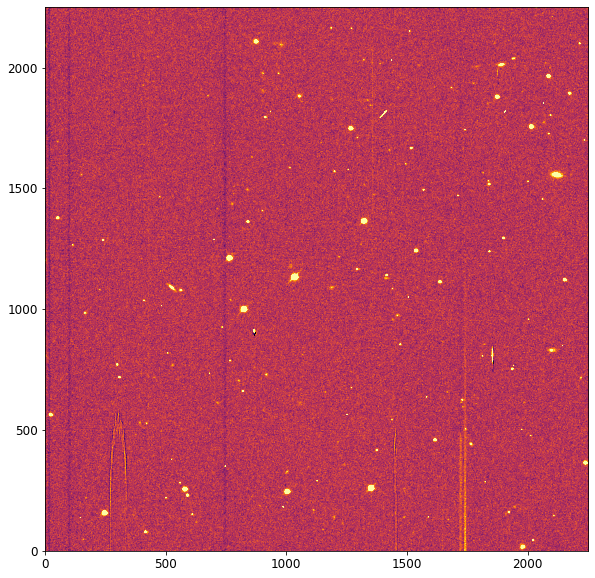

(array([ 10,  28,  29,  31,  32,  34,  35,  37,  62, 105, 107, 108, 111,
       186, 187, 250, 270, 281, 298, 299, 353, 360, 372, 379, 381, 384,
       387, 390, 391, 393, 402, 403, 405, 409, 412, 413]),)
Cluster #6


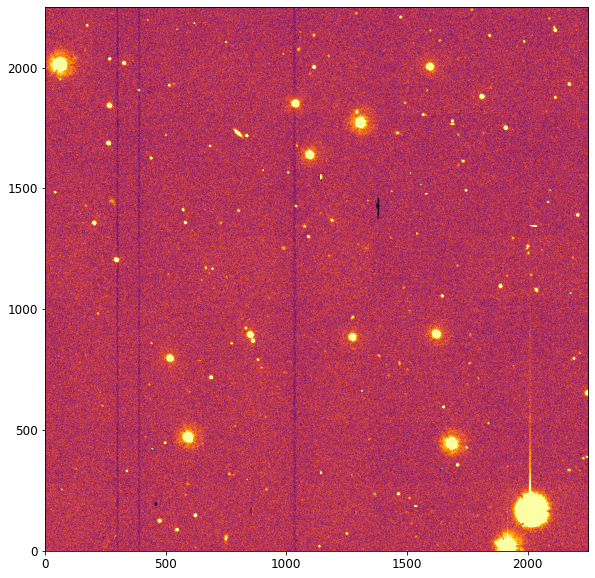

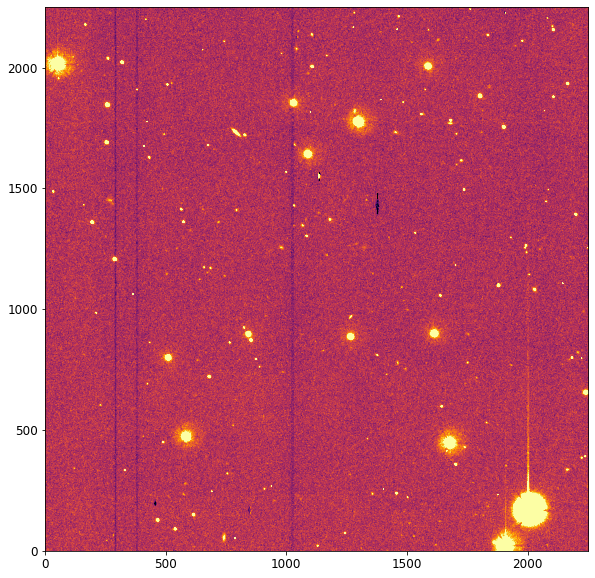

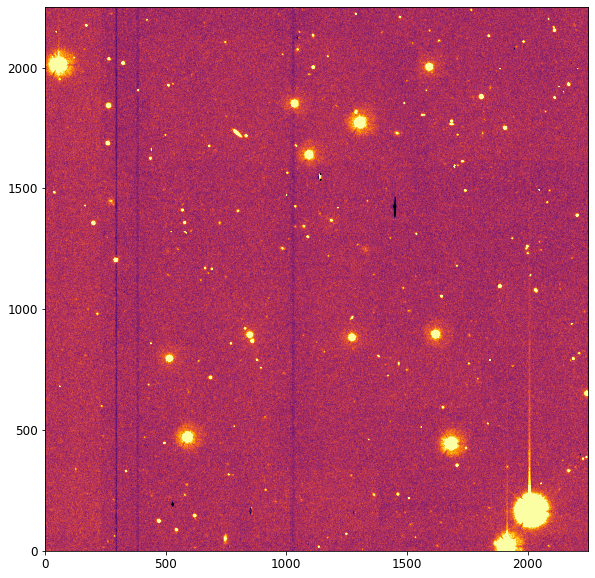

(array([5, 6, 9]),)
Cluster #7


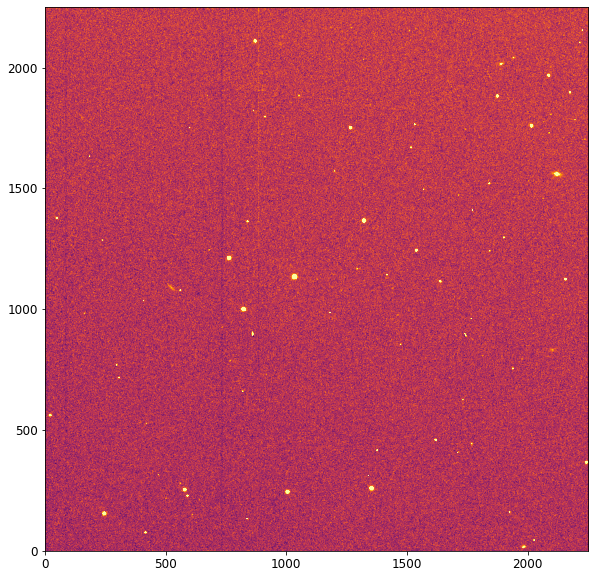

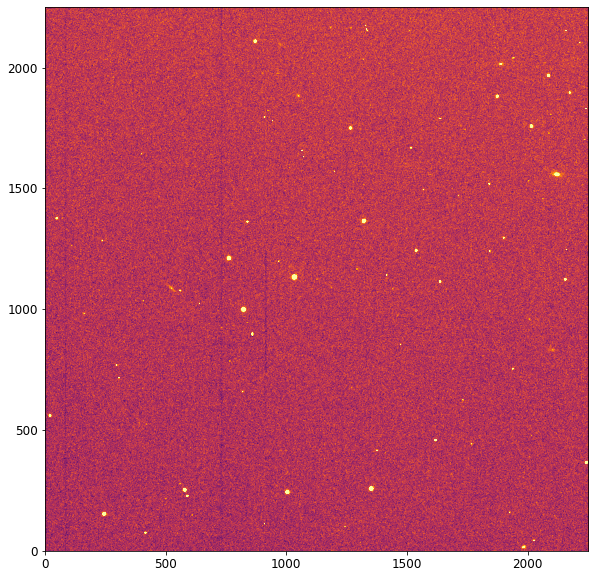

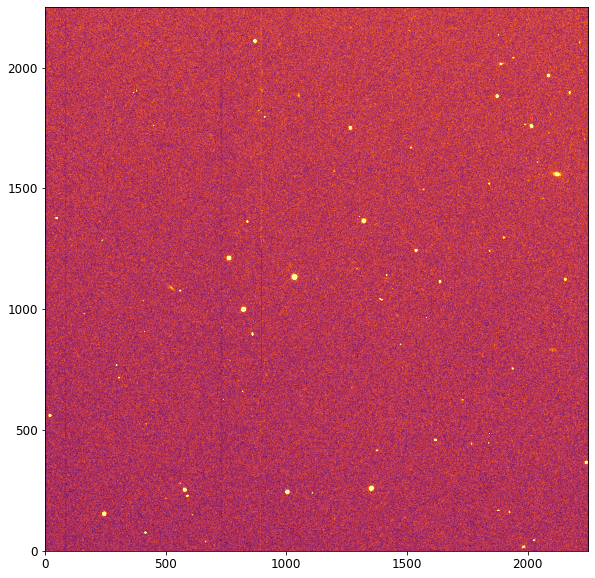

(array([ 77,  80,  83,  90, 116, 117, 119, 123, 142, 145, 147, 156, 157,
       159, 161, 162, 177, 178, 201, 202, 211, 214, 238, 244, 258, 260,
       263, 329, 330, 342, 343, 367]),)
Cluster #8


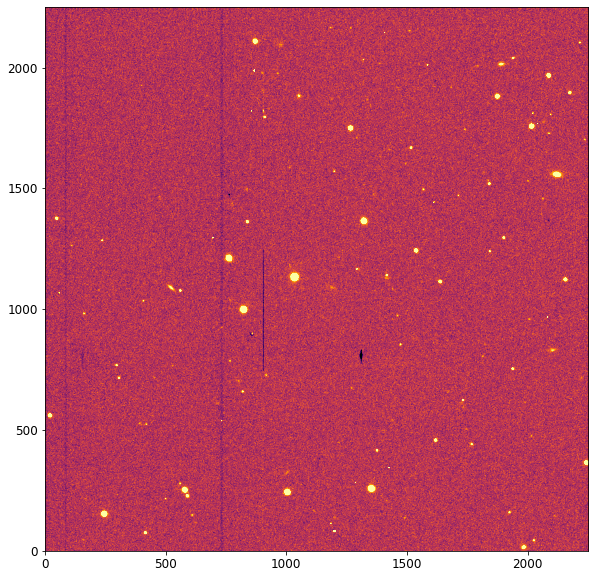

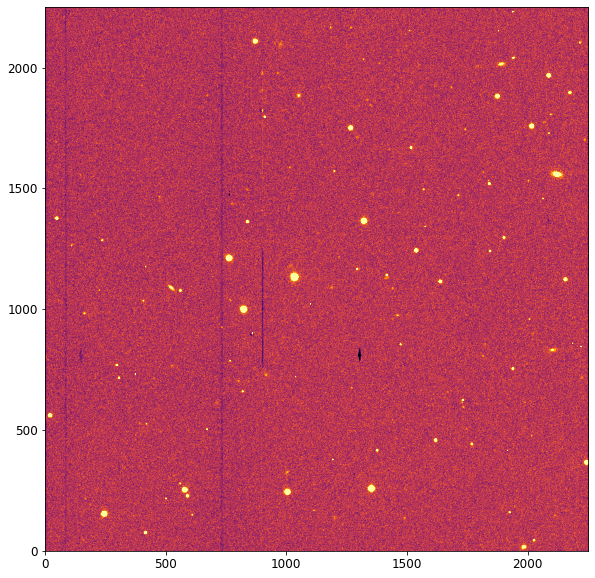

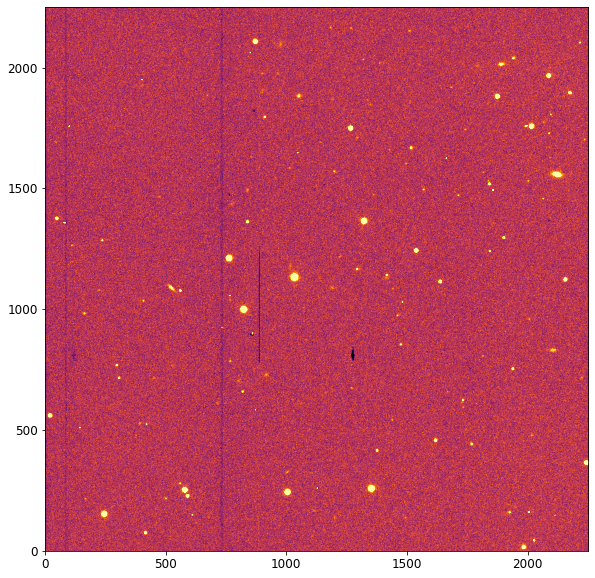

(array([ 24,  25,  26,  43,  44,  48,  74, 185, 207, 218, 227, 229, 231,
       234, 255, 307, 311, 312, 315, 322, 324, 325, 326, 327, 328, 364,
       369, 401]),)
Cluster #9


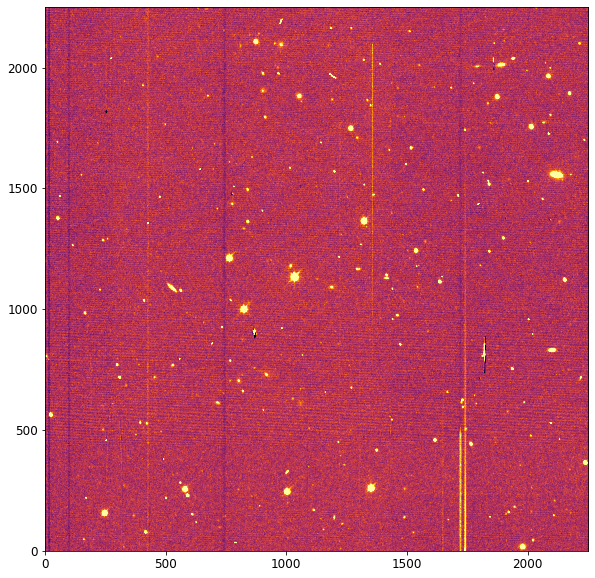

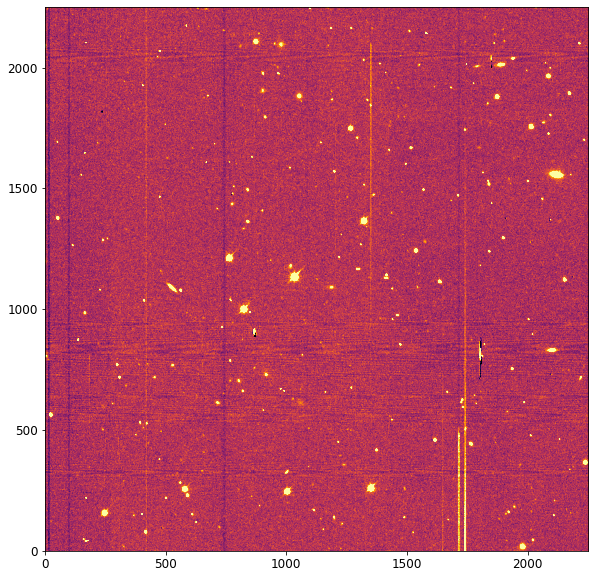

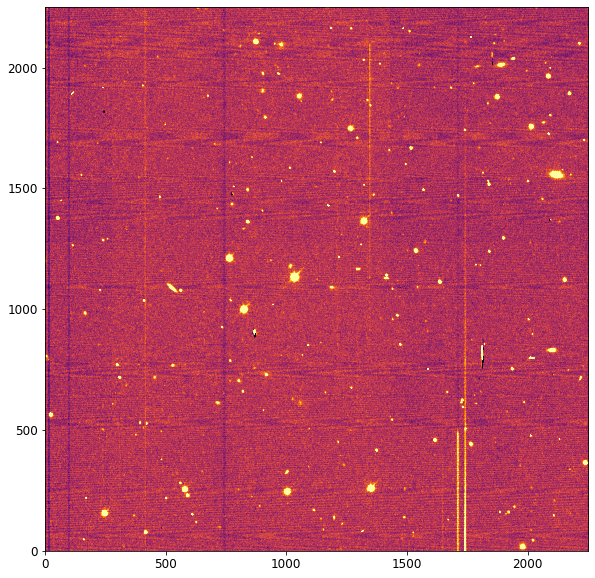

(array([ 40,  41,  42,  57,  88,  89, 192, 195, 196, 198, 199, 242, 246,
       247, 248, 249, 251, 271, 272, 275, 276, 277, 278, 279, 280, 282,
       283, 284, 286, 288, 289, 354, 428, 429, 430]),)
Cluster #10


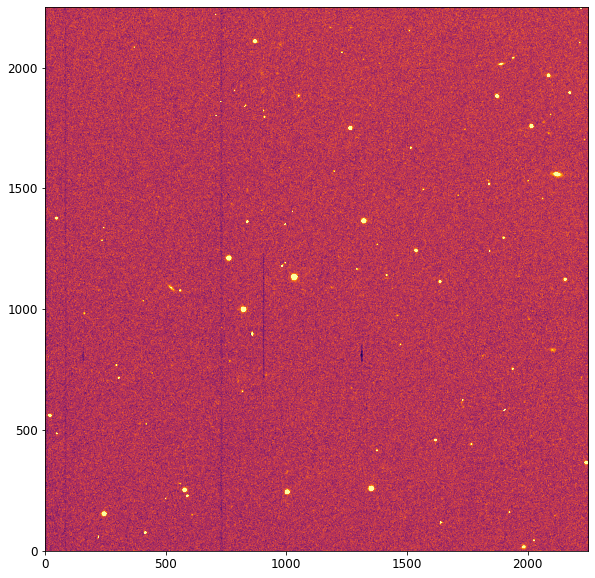

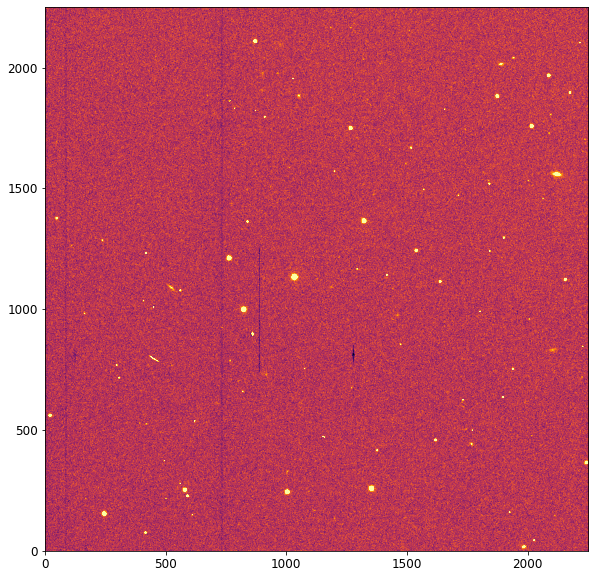

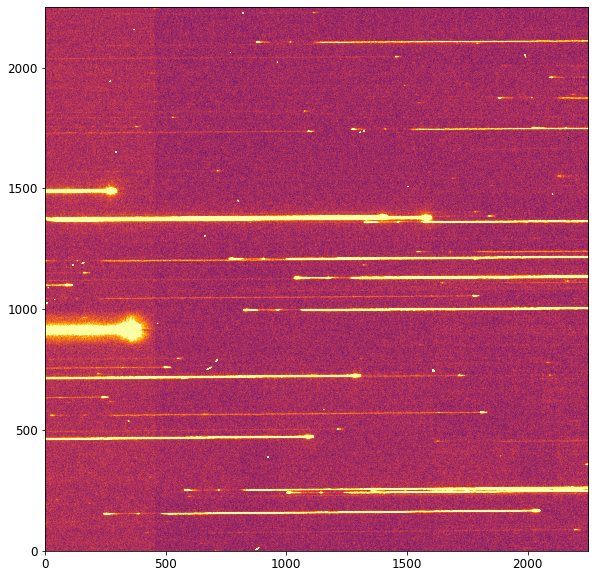

(array([ 45,  46,  56,  75,  76,  81,  82,  85,  97, 101, 120, 125, 126,
       127, 138, 188, 194, 206, 213, 220, 228, 237, 252, 253, 254, 366,
       426]),)
Cluster #11


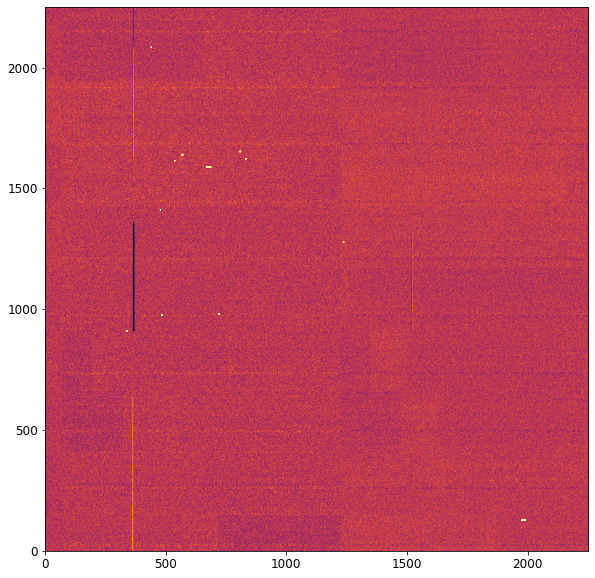

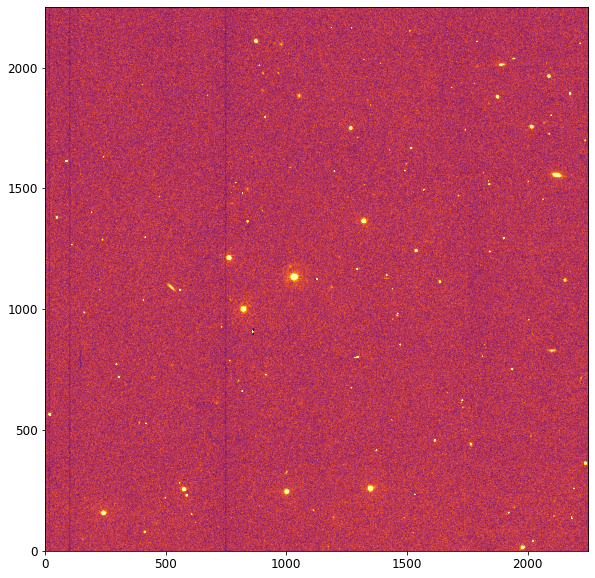

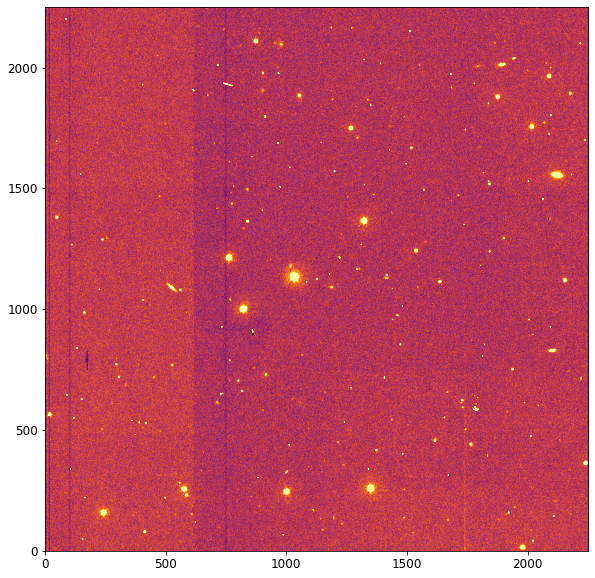

(array([ 27, 140, 290, 291, 316]),)
Cluster #12


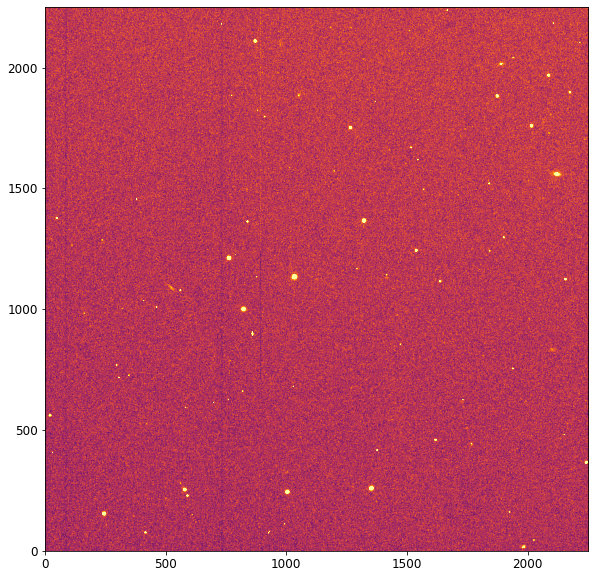

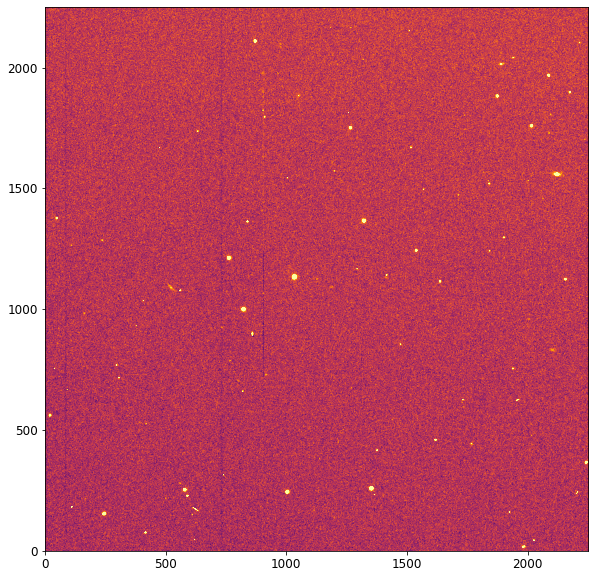

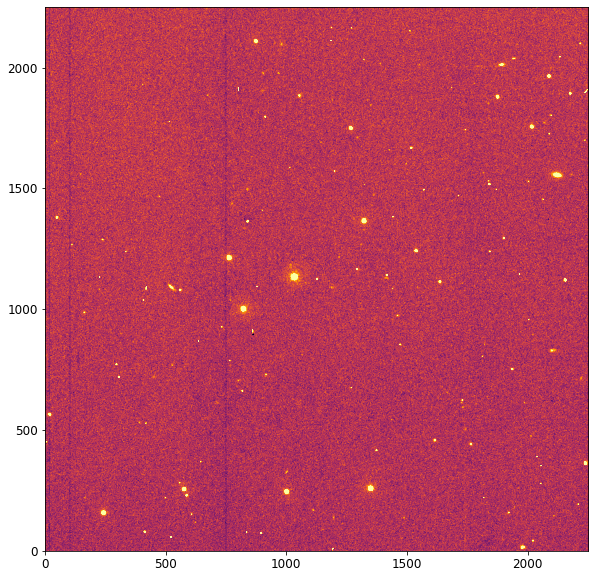

(array([ 78,  79, 102, 124, 130, 132, 143, 146, 153, 154, 155, 158, 160,
       180, 184, 193, 197, 245, 259, 261, 262, 264, 265, 266, 267, 285,
       333, 337, 339]),)
Cluster #13


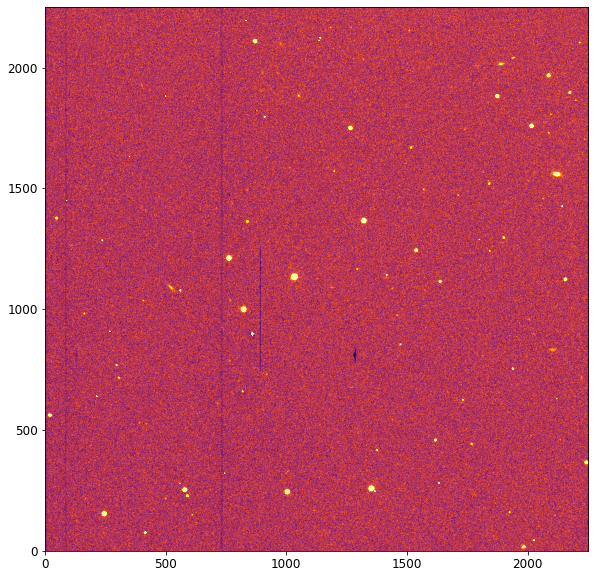

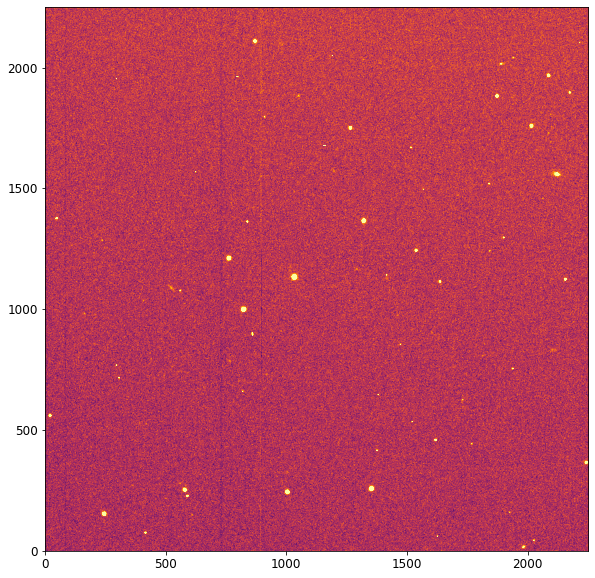

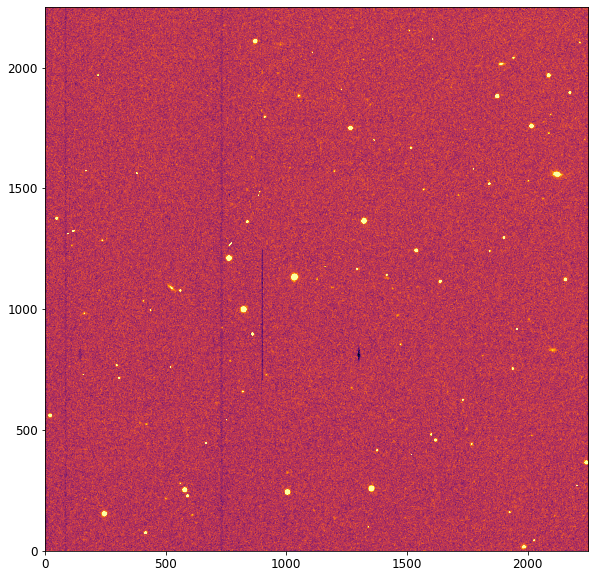

(array([ 47,  84,  94,  95,  96, 118, 128, 190, 215, 217, 219, 221, 232,
       233, 235, 236, 239, 240, 241, 292, 308, 309, 310, 314, 317, 318,
       319, 320, 321, 323, 365, 425, 427]),)
Cluster #14


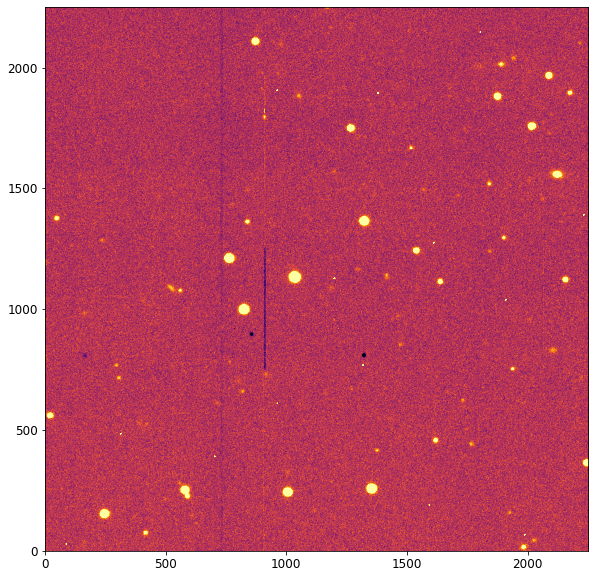

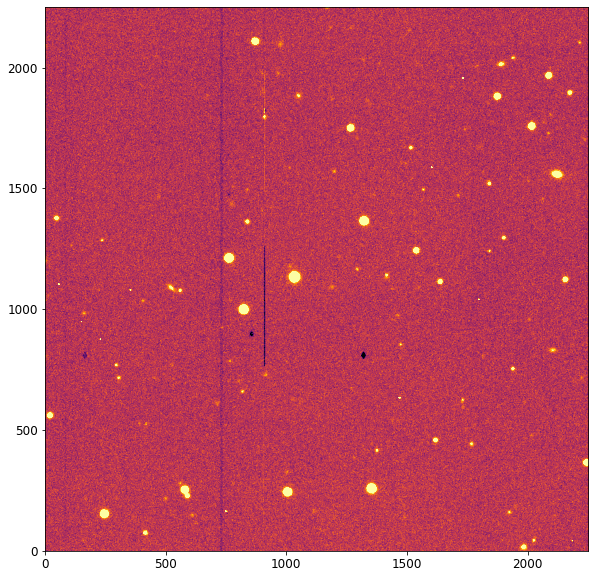

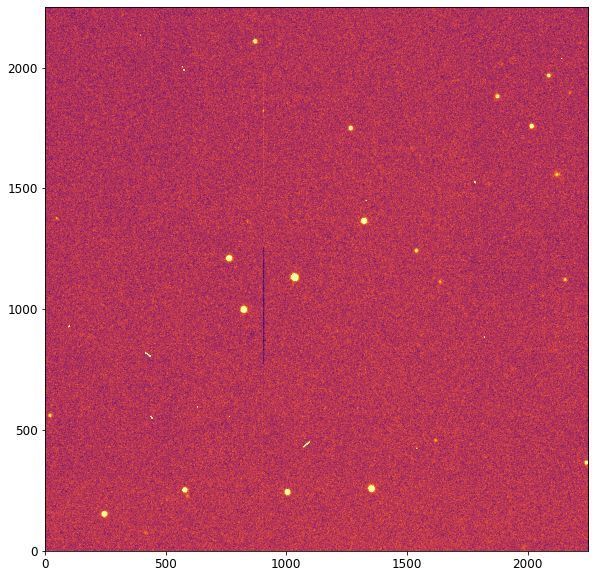

(array([ 13,  14,  15,  16,  17,  18,  19,  20,  22,  55,  91,  93, 100,
       179, 204, 225, 306, 356, 357, 358, 368, 373, 374, 375, 399, 420]),)
Cluster #15


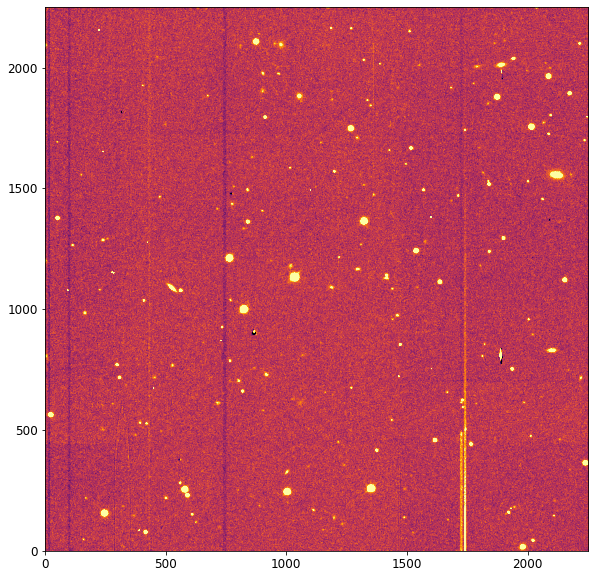

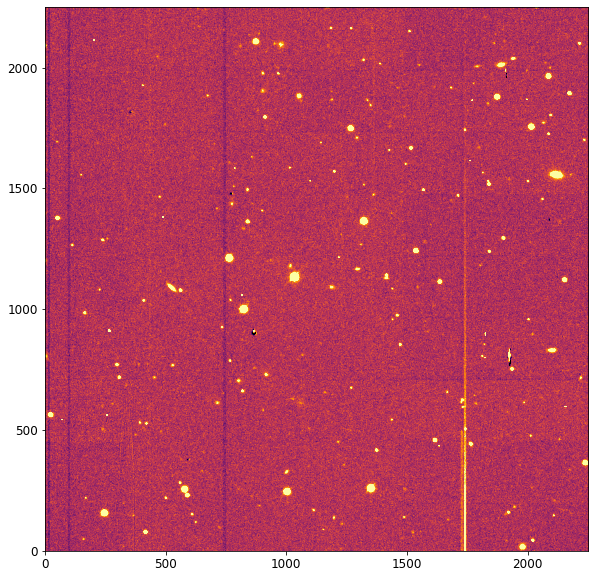

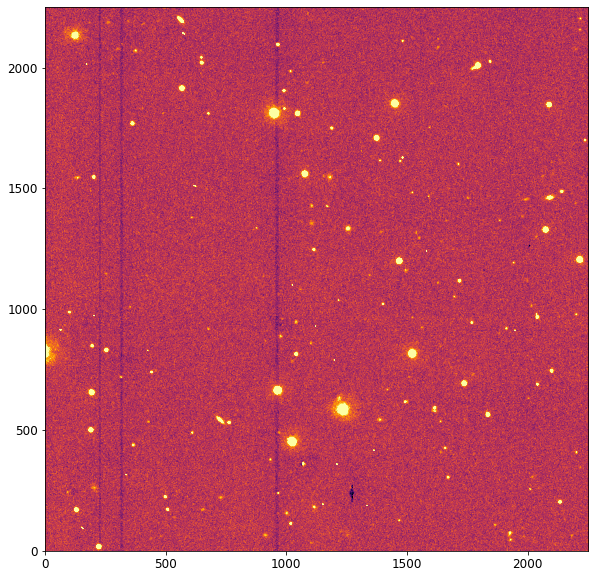

(array([  0,   1,   3,   8,  49,  50,  69,  70,  71,  72,  92,  98, 115,
       165, 166, 167, 205, 208, 268, 269, 295, 296, 297, 313, 346, 351,
       422, 424]),)
Cluster #16


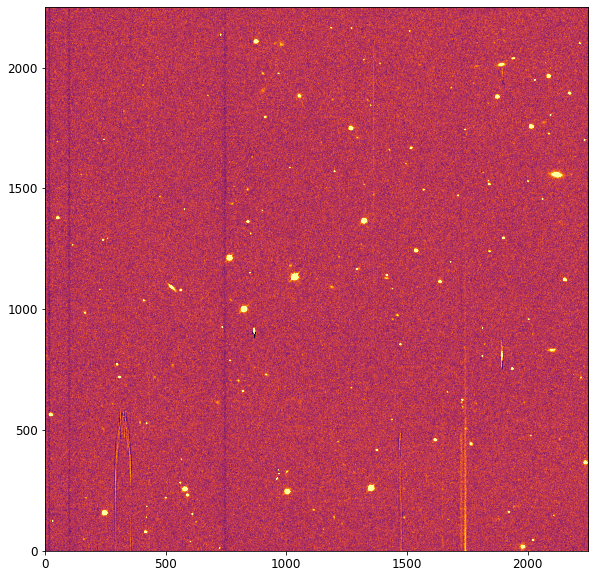

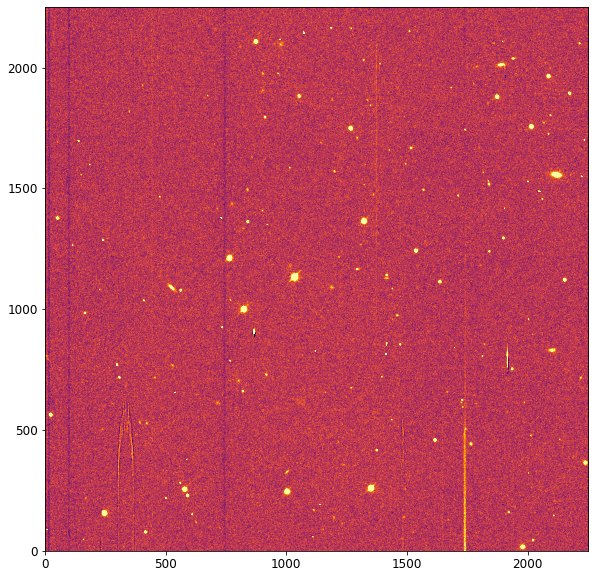

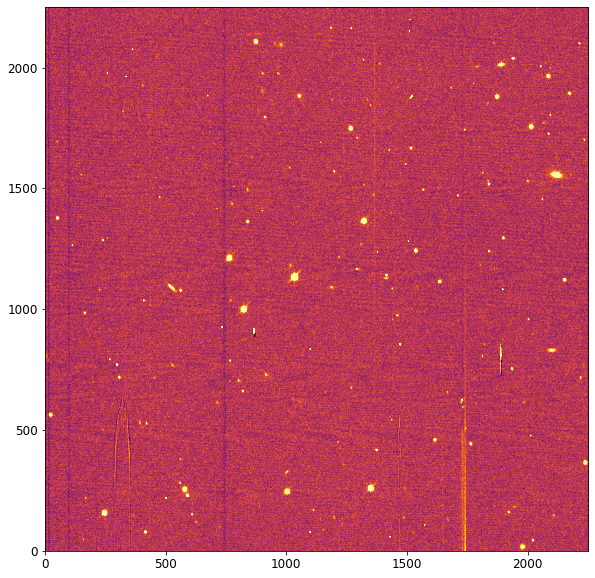

(array([ 30,  36,  38,  39,  58,  59,  60,  86,  87, 106, 109, 274, 287,
       355, 380, 382, 383, 385, 386, 388, 389, 404, 406, 408, 410, 411,
       414, 415, 416, 431, 432]),)
Cluster #17


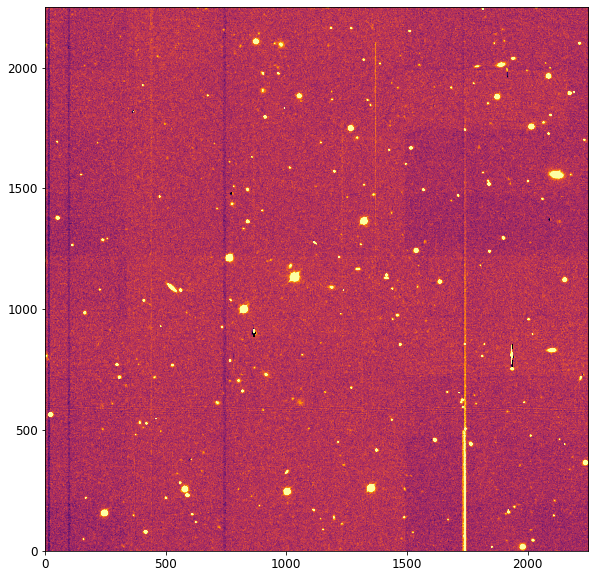

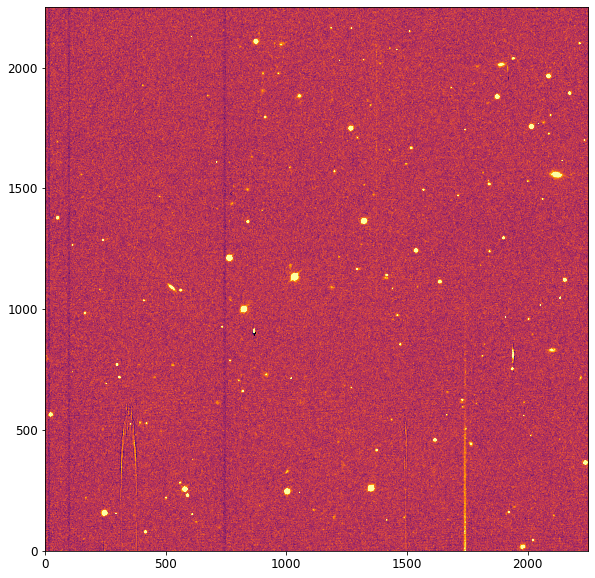

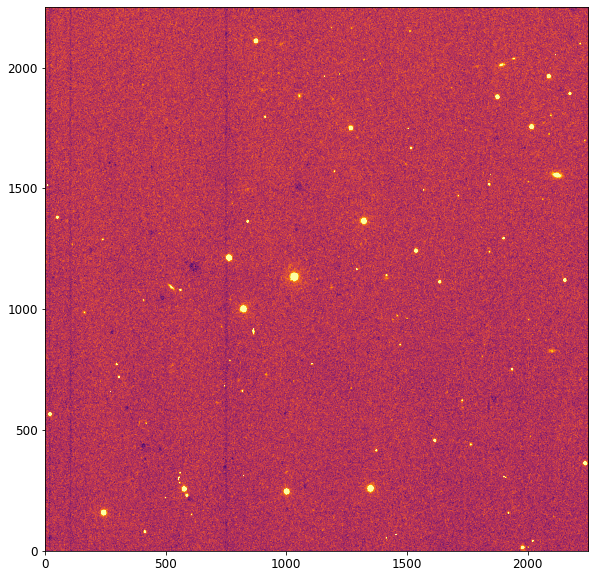

(array([  2,  33,  61,  63,  66,  67, 103, 110, 169, 170, 171, 172, 174,
       176, 191, 209, 210, 243, 293, 300, 301, 302, 349, 350, 359, 361,
       363, 370, 378, 392, 394, 407, 417]),)
Cluster #18


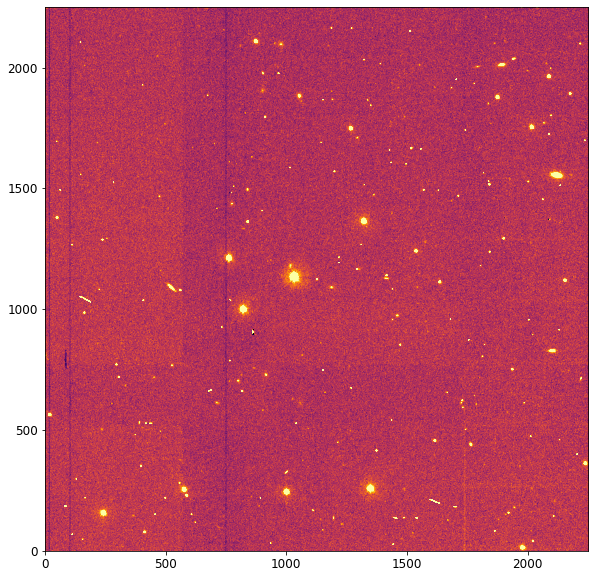

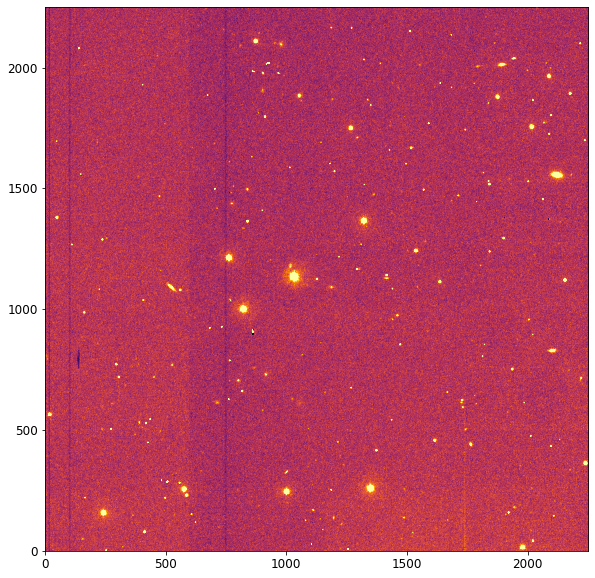

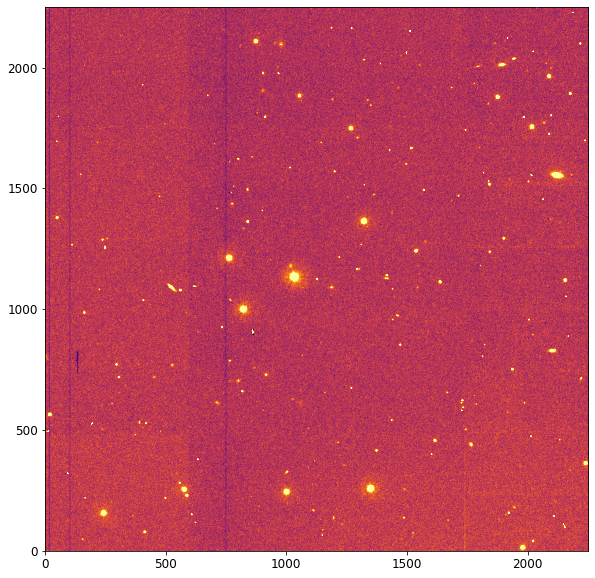

(array([129, 133, 134, 136, 151, 182, 332, 335, 336, 340]),)
Cluster #19


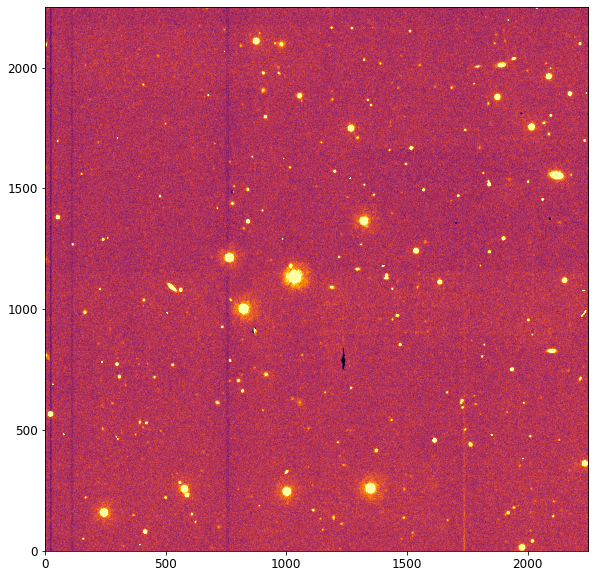

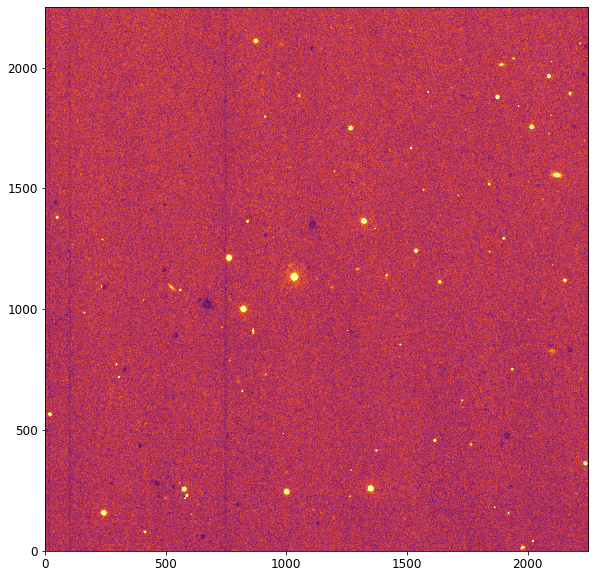

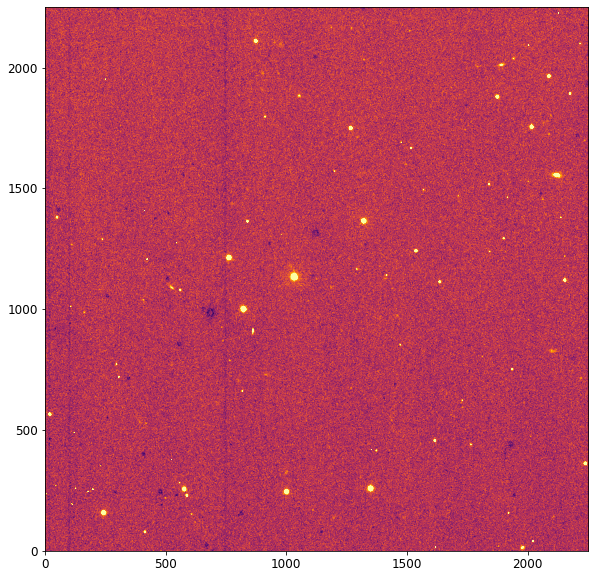

(array([ 11,  64,  65,  68,  73, 104, 113, 168, 173, 175, 294, 303, 304,
       347, 348, 352, 362, 371, 376, 395, 397, 418, 419, 421, 423]),)
Cluster #20


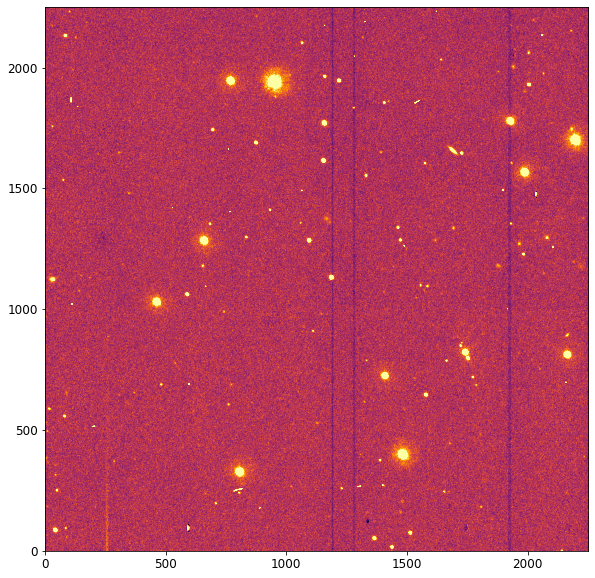

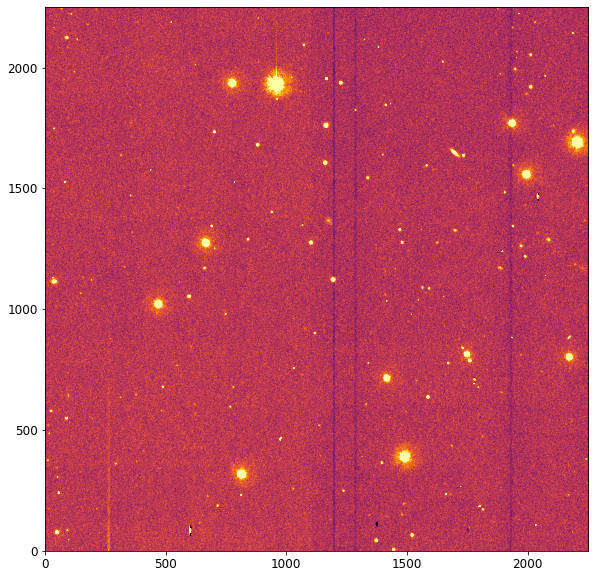

(array([4, 7]),)


In [53]:
print(np.arange(max(labels)+2)+0.5)
plt.hist(labels+1, bins = np.arange(max(labels)+2)+0.5)
plt.show()

for i in range(NUM_CLUSTER):
    print(f"Cluster #{i+1}")
    indices = np.where(labels == i)
    files = img_files[indices]
    for j, f in enumerate(files):
        if j > 2:
            continue
        data = read_file(f)
        plt.figure(figsize=(10,10))
        plt.imshow(data,
                vmin = np.percentile(data,5),
                vmax = np.percentile(data,95),
                origin = 'lower',
                cmap = 'inferno')
        plt.show()
        
    print(indices)